<a href="https://colab.research.google.com/github/Cmay487/Premier_League_Match_Prediction/blob/UpdatedWorkbook_0308/ApplyingProbabilityToFootball.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📄 Notes on the Data


---

## ⚽ Key to Results Data

| Column | Description |
|--------|-------------|
| **Div** | League Division |
| **Date** | Match Date (dd/mm/yy) |
| **Time** | Time of match kick-off |
| **HomeTeam** | Home Team |
| **AwayTeam** | Away Team |
| **FTHG / HG** | Full Time Home Team Goals |
| **FTAG / AG** | Full Time Away Team Goals |
| **FTR / Res** | Full Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |
| **HTHG** | Half Time Home Team Goals |
| **HTAG** | Half Time Away Team Goals |
| **HTR** | Half Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |

---

## 📊 Match Statistics (where available)

| Column | Description |
|--------|-------------|
| **Attendance** | Crowd Attendance |
| **Referee** | Match Referee |
| **HS / AS** | Home / Away Shots |
| **HST / AST** | Home / Away Shots on Target |
| **HHW / AHW** | Home / Away Hit Woodwork |
| **HC / AC** | Home / Away Corners |
| **HF / AF** | Home / Away Fouls Committed |
| **HFKC / AFKC** | Home / Away Free Kicks Conceded |
| **HO / AO** | Home / Away Offsides |
| **HY / AY** | Home / Away Yellow Cards |
| **HR / AR** | Home / Away Red Cards |
| **HBP / ABP** | Home / Away Bookings Points (10 = yellow, 25 = red) |

> **Note 1:** Free Kicks Conceded includes fouls, offsides, and any other offence committed, and will always be equal to or higher than the number of fouls.  
> **Note 2:** English and Scottish yellow cards do not include the initial yellow when a second is shown that becomes a red (European games include it).

---

## 💰 Betting Odds Data (Pre-Closing Odds)

### Bookmaker Codes

| Code | Description |
|------|-------------|
| **B365H / B365D / B365A** | Bet365 home/draw/away odds |


# 📄 Section Notes
---



# Libraries

In [1]:
# funcs
from utils.get_data import extractWebData
from utils.probability import ProbabilityModelling
from utils.plotting import *
from utils.analysis import *
from utils.feature_engineering import *

# standard libraries for EDA
import scipy.stats as stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import (
    binom, beta, poisson, expon, geom, nbinom,
    chi2_contingency
)
warnings.filterwarnings('ignore')

# web scraping
from bs4 import BeautifulSoup
import requests

# machine learning
from catboost import CatBoostClassifier, Pool
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score


# cross validation for time series
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# cross validation scoring
from sklearn.model_selection import cross_val_score

# ML Preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# pca
from sklearn.decomposition import PCA

# feature selection
from sklearn.feature_selection import RFE

# set sns theme
sns.set_theme(style="whitegrid", palette="pastel")



c:\Users\Charl\OneDrive\Python\Projects\Classification\Premier_League_Match_Prediction\utils\get_data.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  prem['Season'] = self.csv_links[i].split('/')[4] # get the season name from the csv string


<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

# Web Scraping the data

In [2]:

# call class as object
scaper = extractWebData('https://www.football-data.co.uk/englandm.php', 8)
df = scaper.run_web_scrape()

df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

# Data Cleaning

## NaN Values

In [3]:
 # count the number of Nan - It should be 1
df.isna().sum().sort_values(ascending=False)

League Division    0
Date               0
Time               0
HomeTeam           0
AwayTeam           0
                  ..
AvgC<2.5           0
AHCh               0
AvgCAHH            0
AvgCAHA            0
Season             0
Length: 62, dtype: int64

## Outliers

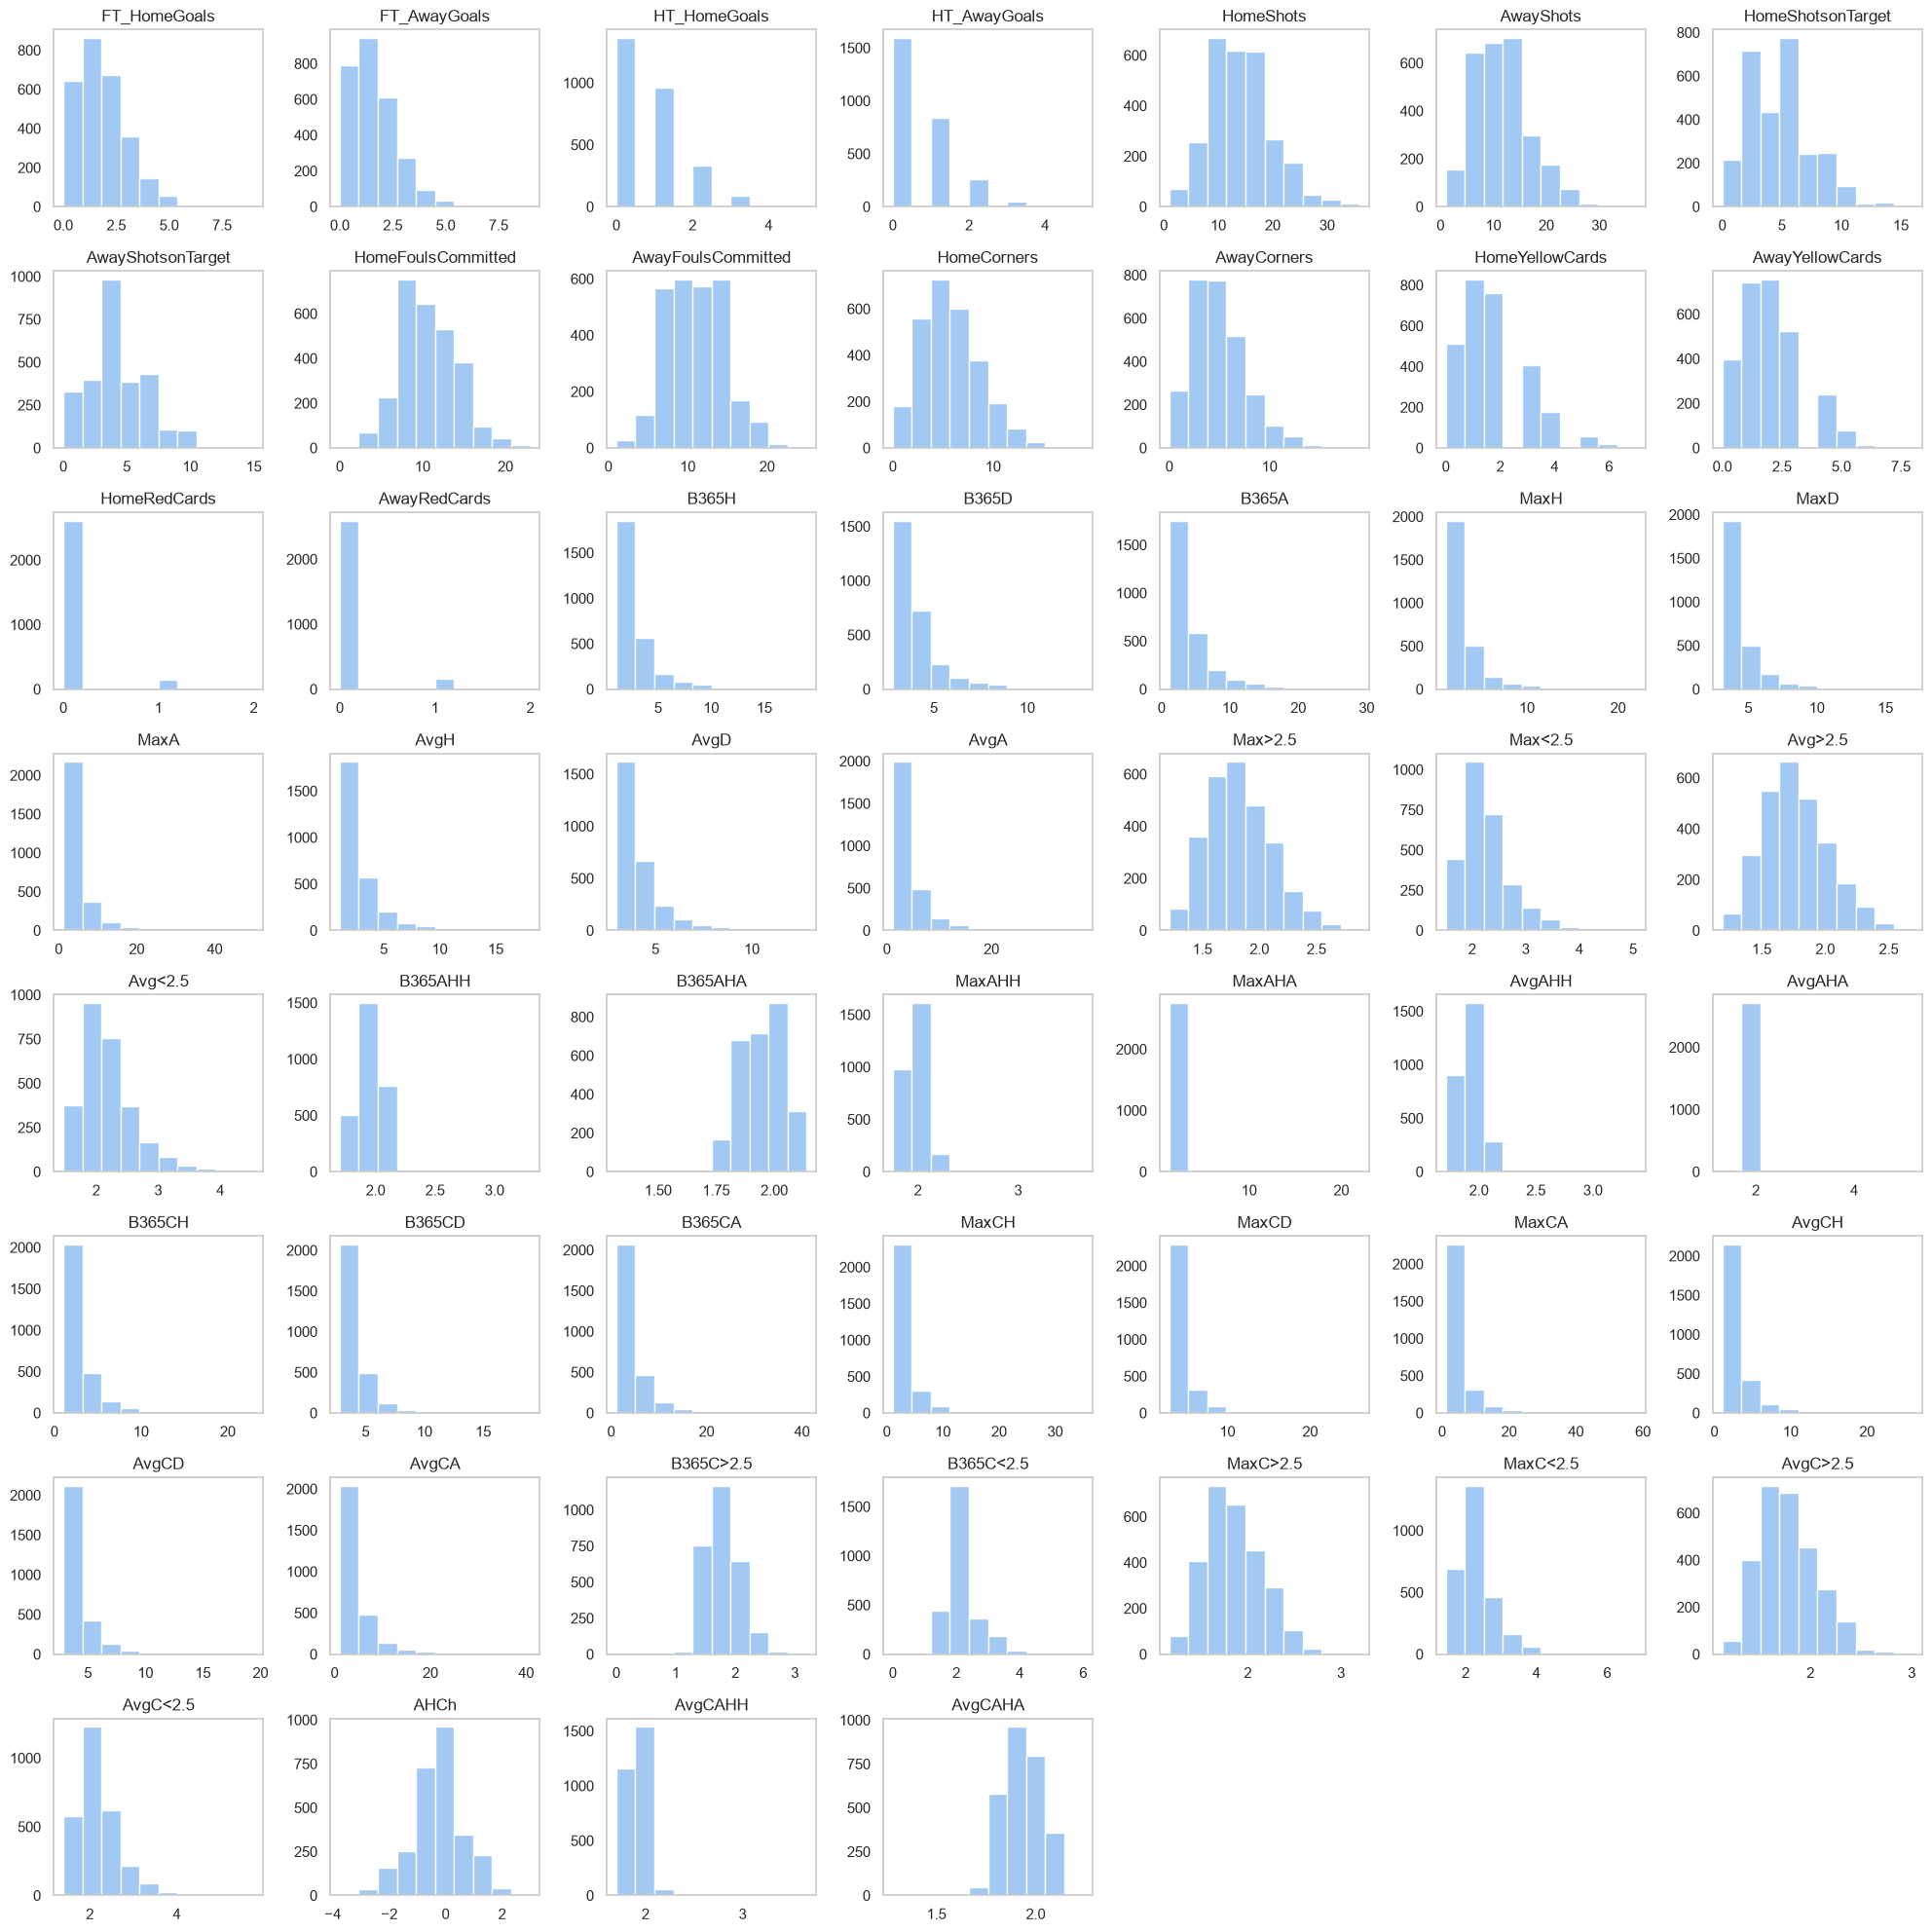

In [4]:
# visualise the distribution to see any outliers
df.hist(figsize=(20,20),grid=False);

plt.tight_layout()

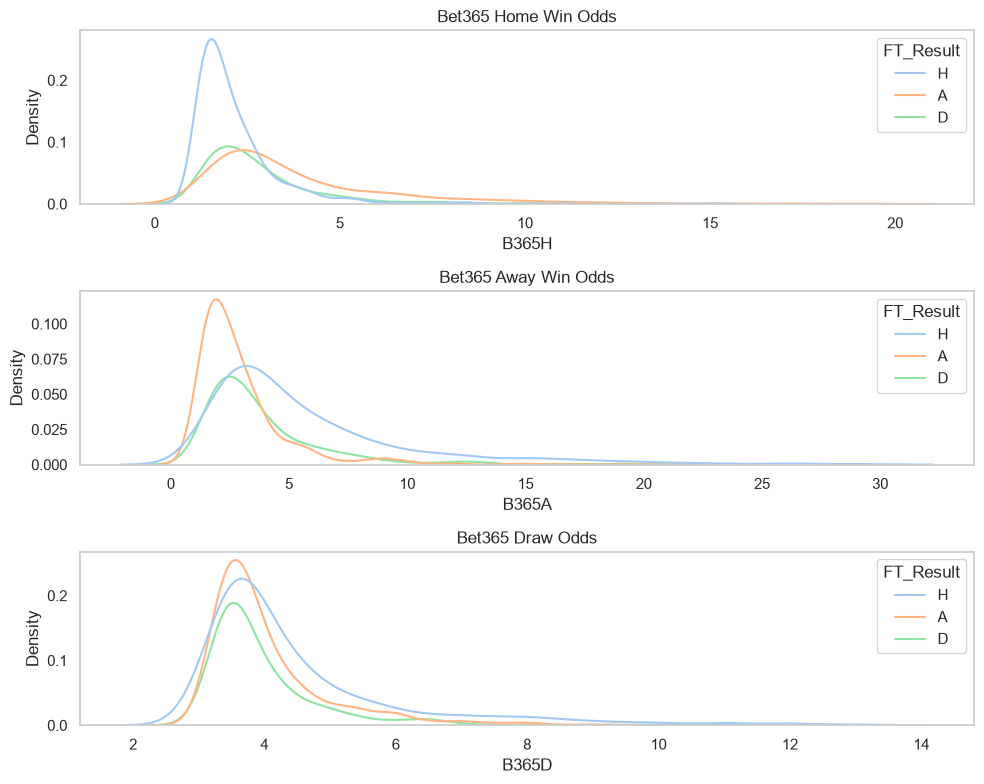

In [5]:
# The Bet365 features look to have extreme values.
# Lets investigate why this and validate if they are true outliers

bet365 = df[['B365H','B365D','B365A','FT_Result']].copy()

fig,axes = plt.subplots(3,1,figsize=(10,8))
sns.kdeplot(data=bet365,x='B365H',hue='FT_Result',ax=axes[0]);
sns.kdeplot(data=bet365,x='B365A',hue='FT_Result',ax=axes[1]);
sns.kdeplot(data=bet365,x='B365D',hue='FT_Result',ax=axes[2]);

axes[0].set_title('Bet365 Home Win Odds');
axes[1].set_title('Bet365 Away Win Odds');
axes[2].set_title('Bet365 Draw Odds');

# remove grid 
for ax in axes:
    ax.grid(False)
    
plt.tight_layout()

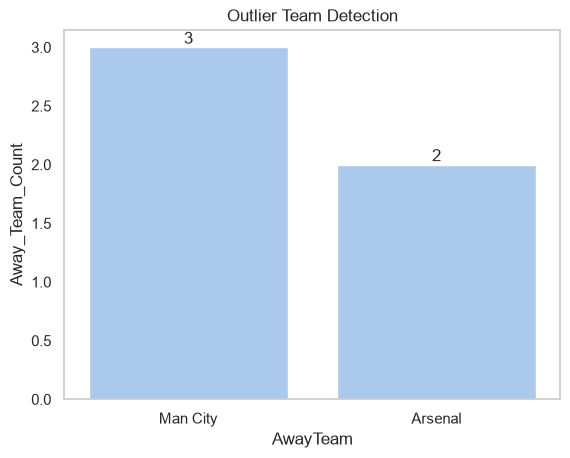

In [6]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365H'] > 15)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('AwayTeam')
            .agg(Away_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Away_Team_Count',ascending=False)
            )

ax = sns.barplot(data=agg_df,x='AwayTeam',y='Away_Team_Count');

for container in ax.containers:
    ax.bar_label(container)

plt.title('Outlier Team Detection')
plt.grid(False)
plt.show()

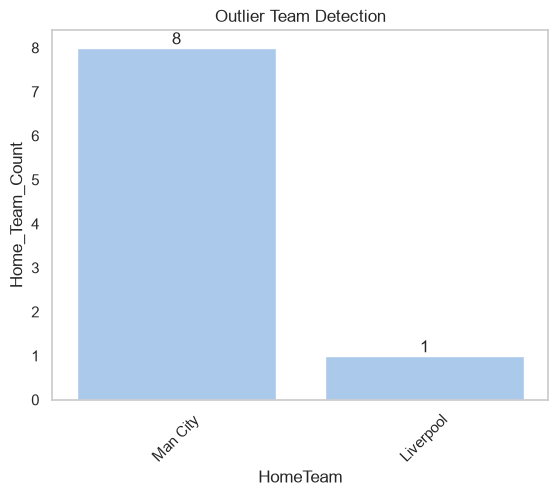

In [7]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365A'] > 25)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('HomeTeam')
            .agg(Home_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Home_Team_Count',ascending=False)
            )

ax = sns.barplot(data=agg_df,x='HomeTeam',y='Home_Team_Count');

for container in ax.containers:
    ax.bar_label(container)

for item in ax.get_xticklabels():
    item.set_rotation(45)

plt.title('Outlier Team Detection')
plt.grid(False)
plt.show()

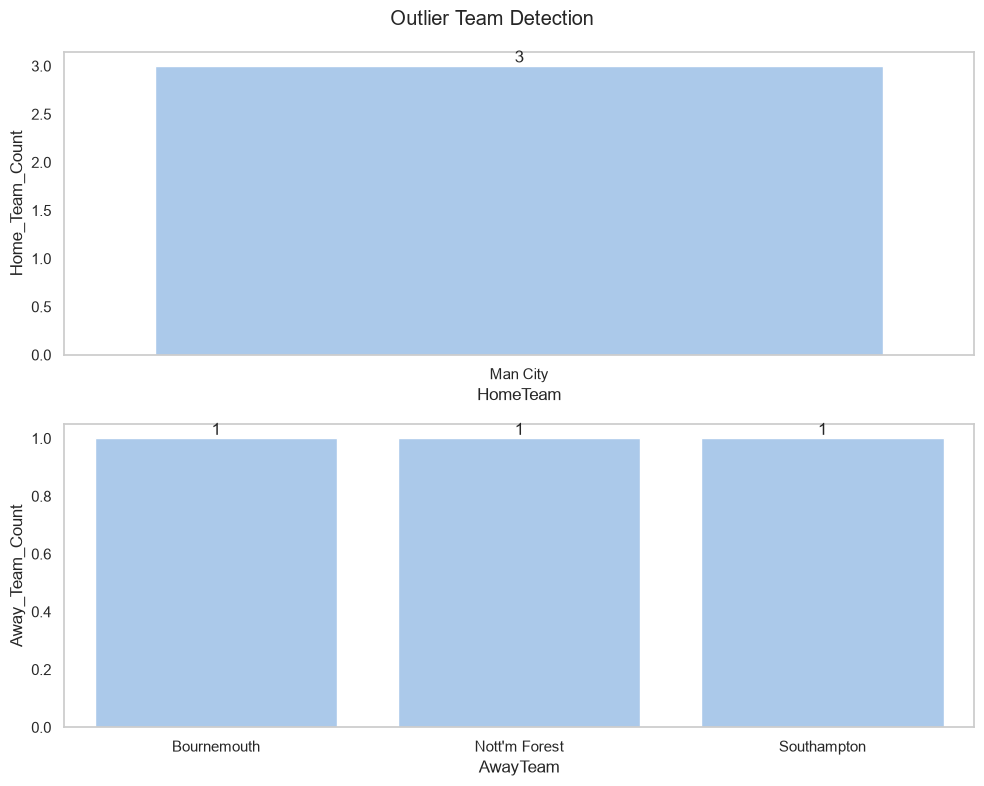

In [8]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365D'] > 12)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('HomeTeam')
            .agg(Home_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Home_Team_Count',ascending=False)
            )

agg_dfb = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('AwayTeam')
            .agg(Away_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Away_Team_Count',ascending=False)
            )

fig,axes = plt.subplots(2,1,figsize=(10,8))

ax = sns.barplot(data=agg_df,x='HomeTeam',y='Home_Team_Count',ax=axes[0]);
ax1 = sns.barplot(data=agg_dfb,x='AwayTeam',y='Away_Team_Count',ax=axes[1]);

bars = [ax,ax1]

for bar in bars:
  for container in bar.containers:
      bar.bar_label(container)


plt.suptitle('Outlier Team Detection')
for ax in axes:
   ax.grid(False)
plt.tight_layout()
plt.show()

**Observations**

Based on the observation in the above analysis, it appears that Bet365 favours higher ranked teams (teams that typically place in the top 4/5 in the league) over lower ranked teams. Therefore, these outliers are true datapoints and will remain in the dataset.

## Data Consistency

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

In [10]:
# Drop league division as this analysis focuses on Premier League
df.drop(columns='League Division',inplace=True)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 61 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                2760 non-null   str    
 1   Time                2760 non-null   str    
 2   HomeTeam            2760 non-null   str    
 3   AwayTeam            2760 non-null   str    
 4   FT_HomeGoals        2760 non-null   int64  
 5   FT_AwayGoals        2760 non-null   int64  
 6   FT_Result           2760 non-null   str    
 7   HT_HomeGoals        2760 non-null   int64  
 8   HT_AwayGoals        2760 non-null   int64  
 9   HT_Result           2760 non-null   str    
 10  Match Referee       2760 non-null   str    
 11  HomeShots           2760 non-null   int64  
 12  AwayShots           2760 non-null   int64  
 13  HomeShotsonTarget   2760 non-null   int64  
 14  AwayShotsonTarget   2760 non-null   int64  
 15  HomeFoulsCommitted  2760 non-null   int64  
 16  AwayFoulsCommitted  276

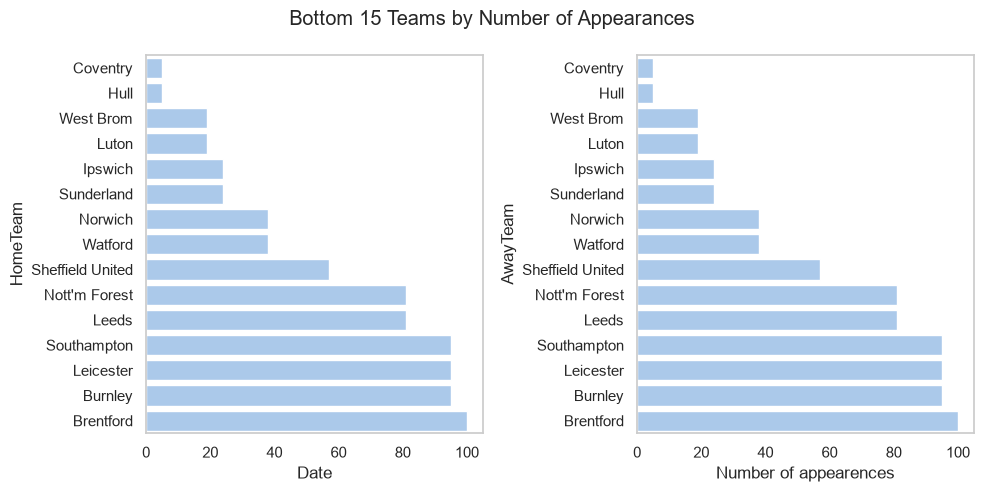

In [12]:
# Focus on the bottom 15 teams as these will be where inconsistent data entries lie.

# agg the data
hteams = (df.groupby('HomeTeam')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)
ateams = (df.groupby('AwayTeam')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)

# visualise
fig,axes = plt.subplots(1,2,figsize=(10,5))
sns.barplot(data=hteams.head(15),x='Date',y='HomeTeam',ax=axes[0]);
sns.barplot(data=ateams.head(15),x='Date',y='AwayTeam',ax=axes[1]);

# clean up the visuals
for ax in axes:
    ax.grid(False)
plt.xlabel('Number of appearences')
plt.suptitle('Bottom 15 Teams by Number of Appearances')
plt.tight_layout()

In [13]:
# there should only be 3 entrues for Full Time Result (H=Home Win, D=Draw, A=Away Win)

df['FT_Result'].value_counts().reset_index()

,FT_Result,count
0,H,1197
1,A,907
2,D,656


There are 45 different Referees in the dataset


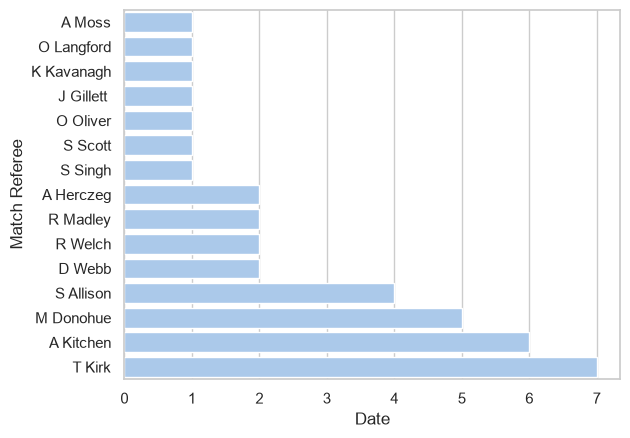

In [14]:
# now take the same approach as home and away teams with refs
# agg the data
refs = (df.groupby('Match Referee')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)

ref_Count = df['Match Referee'].nunique()

print(f'There are {ref_Count} different Referees in the dataset')
sns.barplot(data=refs.head(15),x='Date',y='Match Referee');

## Data Type

In [15]:
# set the match date a date data type

df['Date'].str.rfind('/')

# there were some errors in the date where the year was showing 06 instead of 2006.
# the below corrects this by finding the year with only 2 string values, then changing them to create the
# proper format.
df['Date'] = pd.to_datetime(
    df['Date'].apply(
    lambda x: x[:x.rfind('/')+1] + "20" + x[x.rfind('/')+1:]
    if len(x[x.rfind('/')+1:]) == 2 else x
))

In [16]:
# add in time series features
df['DayofWeek'] = df['Date'].dt.day_name()
df['Month'] = df['Date'].dt.month_name()
df['Year'] = df['Date'].dt.year

# add in season of the year
def season_of_yr(x):
  if x in ['December','January','February']:
    return 'Winter'
  elif x in ['March','April','May']:
    return 'Spring'
  elif x in ['June','July','August']:
    return 'Summer'
  else:
    return 'Autumn'

# create feature
df['SeasonOfYear'] = df['Month'].apply(season_of_yr)

In [17]:
df.head(10)

,Date,Time,HomeTeam,AwayTeam,FT_HomeGoals,FT_AwayGoals,FT_Result,HT_HomeGoals,HT_AwayGoals,HT_Result,...,AvgC>2.5,AvgC<2.5,AHCh,AvgCAHH,AvgCAHA,Season,DayofWeek,Month,Year,SeasonOfYear
0,2026-08-21,20:00,Arsenal,Coventry,3,0,H,2,0,H,...,1.55,2.37,-2.00,2.02,1.74,2627,Friday,August,2026,Summer
1,2026-08-22,12:30,Hull,Man United,2,0,H,2,0,H,...,1.55,2.38,1.50,1.82,1.92,2627,Saturday,August,2026,Summer
2,2026-08-22,15:00,Everton,Crystal Palace,2,0,H,1,0,H,...,1.93,1.83,-0.25,1.96,1.79,2627,Saturday,August,2026,Summer
3,2026-08-22,15:00,Ipswich,Sunderland,2,1,H,1,1,D,...,2.14,1.67,0.00,1.99,1.77,2627,Saturday,August,2026,Summer
4,2026-08-22,15:00,Nott'm Forest,Leeds,0,1,A,0,0,D,...,2.12,1.69,-0.25,2.07,1.70,2627,Saturday,August,2026,Summer
5,2026-08-22,17:30,Brentford,Tottenham,3,0,H,2,0,H,...,1.65,2.18,-0.50,1.95,1.79,2627,Saturday,August,2026,Summer
6,2026-08-23,14:00,Brighton,Aston Villa,4,0,H,4,0,H,...,1.93,1.82,-0.25,1.76,1.98,2627,Sunday,August,2026,Summer
7,2026-08-23,14:00,Man City,Bournemouth,2,1,H,0,1,A,...,1.52,2.45,-1.25,1.90,1.84,2627,Sunday,August,2026,Summer
8,2026-08-23,16:30,Newcastle,Liverpool,2,2,D,1,0,H,...,1.49,2.58,0.50,1.90,1.84,2627,Sunday,August,2026,Summer
9,2026-08-24,20:00,Fulham,Chelsea,2,3,A,1,2,A,...,1.84,1.91,0.50,1.79,1.95,2627,Monday,August,2026,Summer


# EDA

## Data Split

In [18]:
# create train and test set.
# I am going to use the latest season as test set as I want to see how previous seasons
# help the model to predict latest season results

# we wont drop the target for now as will need it to create lagged features - Time Series!!
x_train, x_val, x_test = (
    df.loc[df['Season'].isin(['2324', '2223', '2122', '2021', '1920', '1819'])].copy(),
    df.loc[df['Season'].isin(['2425'])].copy(),
    df.loc[df['Season'].isin(['2526'])].copy()
)

y_train, y_val, y_test = (
    df['FT_Result'].loc[df['Season'].isin(['2324', '2223', '2122', '2021', '1920', '1819'])].copy(),
    df['FT_Result'].loc[df['Season'].isin(['2425'])].copy(),
    df['FT_Result'].loc[df['Season'].isin(['2526'])].copy()
)

# create df for EDA
train_df = df.loc[df['Season'].isin(['2324', '2223', '2122', '2021', '1920', '1819'])].copy().reset_index(drop=True)

## The basics

### Home And Away Stats

In [19]:
# Who has the best home performance?
calculate_win_pct(df=train_df,team='HomeTeam')

FT_Result,HomeTeam,H_pct,D_pct,A_pct
0,Man City,0.778947,0.125288,0.093844
1,Liverpool,0.747368,0.167106,0.083408
2,Arsenal,0.631579,0.177766,0.187873
3,Tottenham,0.631579,0.083654,0.282087
4,Man United,0.568421,0.230202,0.198333
5,Chelsea,0.484211,0.282769,0.229724
6,Aston Villa,0.463158,0.188554,0.345002
7,Newcastle,0.452632,0.303816,0.240193
8,West Ham,0.421053,0.261997,0.313535
9,Wolves,0.410526,0.209620,0.376490


In [20]:
# who has the best away performance?
calculate_win_pct(df=train_df,team='AwayTeam')

FT_Result,AwayTeam,H_pct,D_pct,A_pct
0,Man City,0.178947,0.147091,0.671380
1,Liverpool,0.200000,0.252101,0.544776
2,Arsenal,0.305263,0.188867,0.502649
3,Chelsea,0.336842,0.209782,0.450042
4,Man United,0.315789,0.241303,0.439528
5,Tottenham,0.347368,0.293663,0.355496
6,Aston Villa,0.473684,0.188534,0.334510
7,West Ham,0.505263,0.178001,0.313534
8,Newcastle,0.463158,0.219980,0.313535
9,Brighton,0.389474,0.314500,0.292569


**Notes**

1. You have the "Big 6" Teams in the top end of the matrix showing their superioirty in the league within this sampled dataset.
2. You can also see the newer teams that enter the league who appear to struggle to stay up due to poor win rates at home and away, showing the big gap between Championship and Premier League Football!

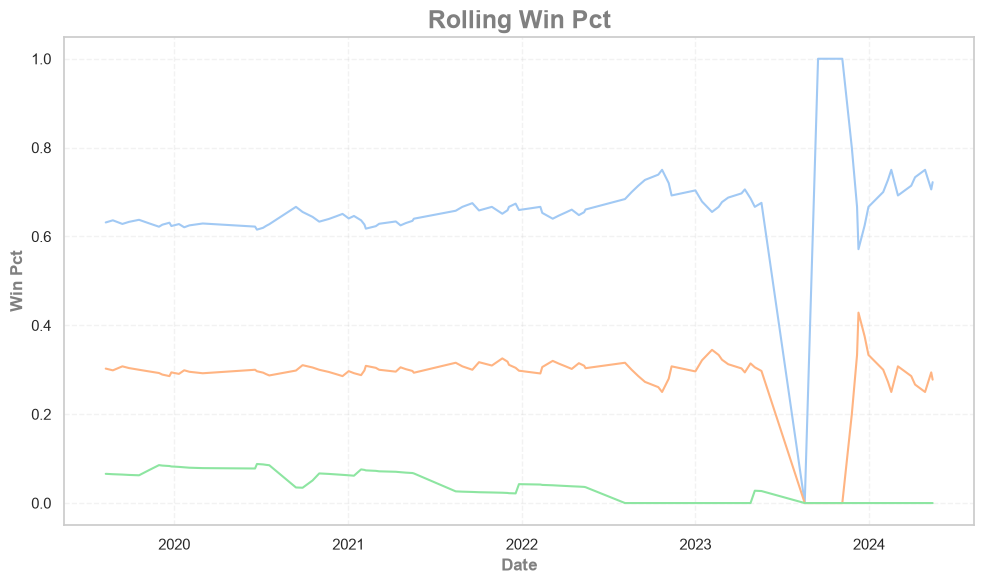

In [21]:
testing_df = rolling_win_pct(train_df,'HomeTeam')

tot_df = testing_df.loc[testing_df['HomeTeam']=='Tottenham']

# verify the results
plt.figure(
    figsize=(10,6)
)
sns.lineplot(
    data=tot_df,
    x=tot_df['Date'],
    y='HomeTeamHomeWinPct'
)

sns.lineplot(
    data=tot_df,
    x=tot_df['Date'],
    y='HomeTeamAwayWinPct'
)

sns.lineplot(
    data=tot_df,
    x=tot_df['Date'],
    y='HomeTeamDrawPct'
)

# adjsut visuals
adjust_visuals(
    title="Rolling Win Pct",
    x_label="Date",
    y_label="Win Pct"
)

In [22]:
# apply the logic to train, validate and test
train_df = rolling_win_pct(train_df,'HomeTeam')
train_df = rolling_win_pct(train_df,'AwayTeam')

x_train = rolling_win_pct(x_train,'HomeTeam')
x_train = rolling_win_pct(x_train,'AwayTeam')

x_val = rolling_win_pct(x_val,'HomeTeam')
x_val = rolling_win_pct(x_val,'AwayTeam')

x_test = rolling_win_pct(x_test,'HomeTeam')
x_test = rolling_win_pct(x_test,'AwayTeam')

In [23]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 1900 entries, 0 to 379
Data columns (total 71 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                1900 non-null   datetime64[us]
 1   Time                1900 non-null   str           
 2   HomeTeam            1900 non-null   str           
 3   AwayTeam            1900 non-null   str           
 4   FT_HomeGoals        1900 non-null   int64         
 5   FT_AwayGoals        1900 non-null   int64         
 6   FT_Result           1900 non-null   str           
 7   HT_HomeGoals        1900 non-null   int64         
 8   HT_AwayGoals        1900 non-null   int64         
 9   HT_Result           1900 non-null   str           
 10  Match Referee       1900 non-null   str           
 11  HomeShots           1900 non-null   int64         
 12  AwayShots           1900 non-null   int64         
 13  HomeShotsonTarget   1900 non-null   int64         
 14  AwayShots

### Match Outcome

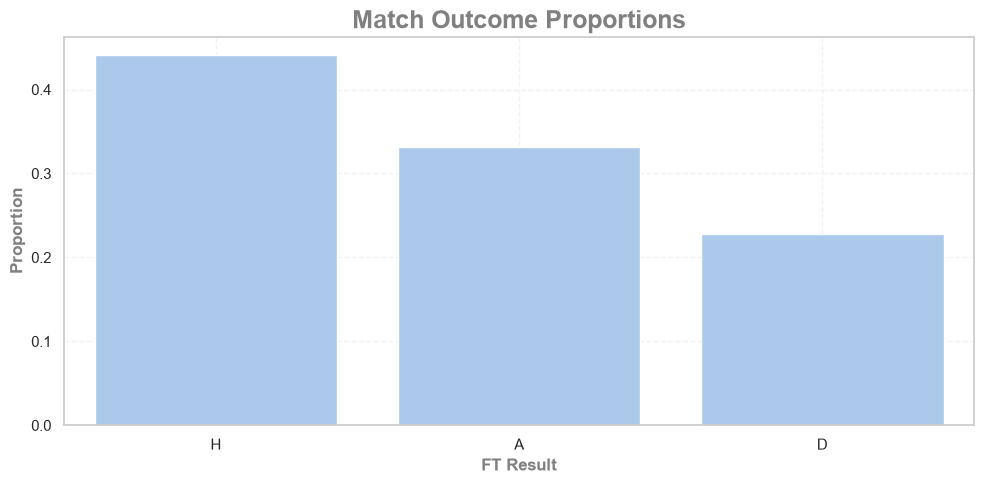

In [24]:
# WHat are the proportions of home win, Draw and Away Win?
p = (
    train_df['FT_Result']
    .value_counts(normalize=True)
    .reset_index()
)

# visualise the results
plt.figure(
    figsize=(10,5)
)

sns.barplot(
    data=p,
    x='FT_Result',
    y='proportion'
);

adjust_visuals(
    title="Match Outcome Proportions",
    x_label="FT Result",
    y_label="Proportion"
    )

**Notes**

1. Draws are the miority class.
2. Home wins are majority class -> Home advantage!
3. Away wins is not too far behind!
4. Home wins are going to be easier to predict due to being the dominant class while Draws will be difficult -> Minority class

### Match Shots

In [25]:
# review shot data at a glance
train_df[['HomeShots','AwayShots','HomeShotsonTarget','AwayShotsonTarget']].describe()


,HomeShots,AwayShots,HomeShotsonTarget,AwayShotsonTarget
count,1900.000000,1900.000000,1900.000000,1900.000000
mean,13.868421,11.598421,4.824737,4.109474
std,5.755008,5.188627,2.641133,2.427596
min,1.000000,1.000000,0.000000,0.000000
25%,10.000000,8.000000,3.000000,2.000000
50%,13.000000,11.000000,5.000000,4.000000
75%,17.000000,15.000000,6.000000,5.000000
max,36.000000,31.000000,15.000000,15.000000


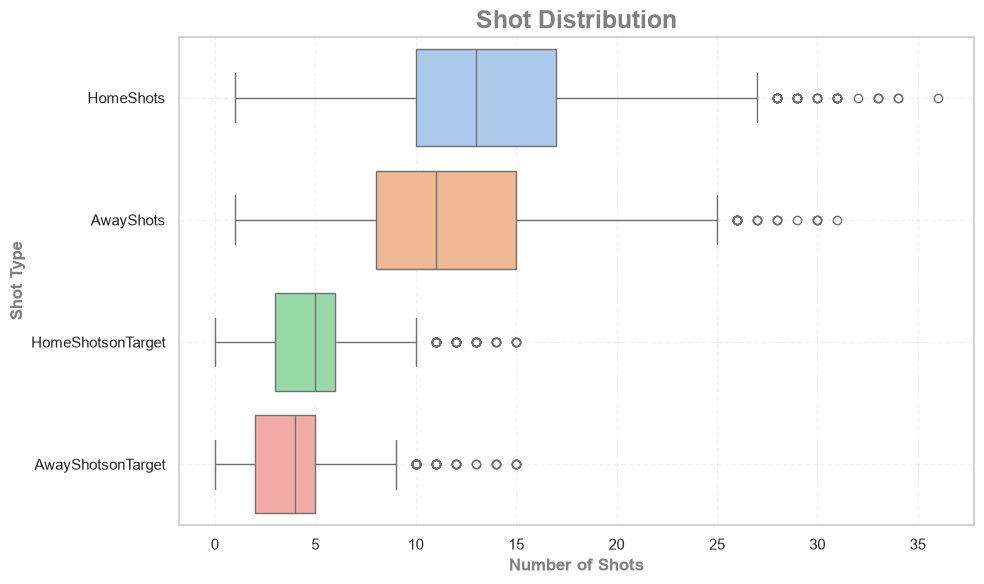

In [26]:
# show the distributions
plt.figure(
    figsize=(10,6)
)
sns.boxplot(
    data=train_df[['HomeShots','AwayShots','HomeShotsonTarget','AwayShotsonTarget']],
    orient='h'
)

adjust_visuals(
    title="Shot Distribution",
    x_label="Number of Shots",
    y_label="Shot Type"
)

In [27]:
# lets group by the result to see what happens to shots on target data
train_df[['HomeShotsonTarget','AwayShotsonTarget','FT_Result']].groupby('FT_Result').describe()

HomeShotsonTarget                                                \
                      count      mean       std  min  25%  50%  75%   max   
FT_Result                                                                   
A                     630.0  3.449206  2.129315  0.0  2.0  3.0  5.0  11.0   
D                     432.0  4.400463  2.288740  0.0  3.0  4.0  6.0  15.0   
H                     838.0  6.077566  2.575493  1.0  4.0  6.0  8.0  15.0   

          AwayShotsonTarget                                                
                      count      mean       std  min  25%  50%  75%   max  
FT_Result                                                                  
A                     630.0  5.592063  2.549404  1.0  4.0  5.0  7.0  15.0  
D                     432.0  3.902778  2.120454  0.0  2.0  4.0  5.0  11.0  
H                     838.0  3.101432  1.864713  0.0  2.0  3.0  4.0  10.0

In [28]:
# create a contringency table of the total count of shots on target by ft result
contingency_table = (
    train_df[['HomeShotsonTarget','AwayShotsonTarget','FT_Result']]
    .groupby('FT_Result')
    .sum()
    .reset_index()
)

add_matrix_colour(contingency_table,title="Contingency Table for total shots on target")



,FT_Result,HomeShotsonTarget,AwayShotsonTarget
0,A,2173,3523
1,D,1901,1686
2,H,5093,2599


#### Shots On Target

In [30]:
def bucket_shots_OT(shots):
    if shots >= 8:
        return '8+'
    elif shots >= 4:
        return '4-7'
    else:
        return '0-3'

train_df['HomeShotsOTBucket'] = train_df['HomeShotsonTarget'].apply(bucket_shots_OT)
train_df['AwayShotsOTBucket'] = train_df['AwayShotsonTarget'].apply(bucket_shots_OT)



# create a contringecy table
contingency_table_(
    col1=train_df['HomeShotsOTBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Homeshots on target"
)



FT_Result,A,D,H
HomeShotsOTBucket,,,
0-3,347,160,133
4-7,256,234,486
8+,27,38,219


In [31]:
# create a contringecy table for away shots
# create a contringecy table
contingency_table_(
    col1=train_df['AwayShotsOTBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Away shots on target"
)

FT_Result,A,D,H
AwayShotsOTBucket,,,
0-3,139,208,527
4-7,360,194,291
8+,131,30,20


In [32]:
# do we observe simpson paradox when we introduce homeshots
# create a contringecy table
contingency_table_(
    col1=train_df['HomeShotsOTBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Home and Away shots on target",
    col2=train_df['AwayShotsOTBucket']
)

**Notes**

1. It appears that the more shots on target generally leads to a victory for the team - however, I must conduct CHi2 test to confirm this.
2. A draw tends to happen when the shots on target a relatively equal for both sides.
3. This feature is a great proxy for how well a team a team performs, as we do not have access to xG.

In [33]:
"""
====================================
My test:
====================================

h0: There is no dependency between shots on target and the result of the game.
h1: There is a dependency between shots on target and the result of the game.

"""
# save data as tbl
ct_home = pd.crosstab(
    train_df['HomeShotsOTBucket'],
    train_df['FT_Result']
)

# conduct a chi2 test on shots on target data
conduct_chi2(ct_home,confidence=0.05)


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 316.95
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[212.21052632 145.51578947 282.27368421]
 [323.62105263 221.91157895 430.46736842]
 [ 94.16842105  64.57263158 125.25894737]]
**************************************************


In [34]:
"""
====================================
My test:
====================================

h0: There is no dependency between shots on target and the result of the game.
h1: There is a dependency between shots on target and the result of the game.

"""
# save data as tbl
ct_away = pd.crosstab(
    train_df['AwayShotsOTBucket'],
    train_df['FT_Result']
)

# conduct a chi2 test on shots on target data
conduct_chi2(ct_away,confidence=0.05)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 303.34
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[289.8        198.72       385.48      ]
 [280.18421053 192.12631579 372.68947368]
 [ 60.01578947  41.15368421  79.83052632]]
**************************************************


In [35]:
"""
====================================
My test:
====================================

h0: There is no dependency between shots on target and the result of the game.
h1: There is a dependency between shots on target and the result of the game.

The below should see if the new variable influences the contingency table

"""
# save data as tbl
ct_home_away = pd.crosstab(
    [train_df['HomeShotsOTBucket'],train_df['AwayShotsOTBucket']],
    train_df['FT_Result']
)

# conduct a chi2 test on shots on target data
conduct_chi2(ct_home_away,confidence=0.05)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 571.09
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 77.92105263  53.43157895 103.64736842]
 [102.78947368  70.48421053 136.72631579]
 [ 31.5         21.6         41.9       ]
 [155.17894737 106.40842105 206.41263158]
 [144.23684211  98.90526316 191.85789474]
 [ 24.20526316  16.59789474  32.19684211]
 [ 56.7         38.88        75.42      ]
 [ 33.15789474  22.73684211  44.10526316]
 [  4.31052632   2.95578947   5.73368421]]
**************************************************


**Notes**

All the Chi2 Tests show dependency between the feature and target! This means that the more shots on target a team gets, the greater the likelyhood of them winning the game.

In terms of ML, we have successfully created a feature that extracts signal from the feature as the data shows a scale-like system - the higher the shots on target for either home or away team, the result will likely go their way. On the other hand, an even match (as shown with similar shots on target amount) shows an even likelihhod of the match outcome.

However, this data is in game which is information that we will not have for upcoming matches. Therefore, lagged features is the best option to use as a proxy for team performance in matches. I will create the following:

1. Last 5 home game average shots on target.
2. Last 5 away game average shots on target.
3. Last 5 home game average shots on target conceded.
4. Last 5 away game average shots on target conceded.

In [36]:
train_df = lagged_shots_feature(train_df,'HomeTeam','HomeShotsonTarget')
train_df = lagged_shots_feature(train_df,'AwayTeam','AwayShotsonTarget')

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1900 entries, 0 to 1899
Data columns (total 81 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Date                                     1900 non-null   datetime64[us]
 1   Time                                     1900 non-null   str           
 2   HomeTeam                                 1900 non-null   str           
 3   AwayTeam                                 1900 non-null   str           
 4   FT_HomeGoals                             1900 non-null   int64         
 5   FT_AwayGoals                             1900 non-null   int64         
 6   FT_Result                                1900 non-null   str           
 7   HT_HomeGoals                             1900 non-null   int64         
 8   HT_AwayGoals                             1900 non-null   int64         
 9   HT_Result                                1900 non-nu

In [37]:
"""
Lets see what the new feature looks like.

I had to adjust the buckets because we are taking mean so we can still account
for larger shots OT count in previous matches.
"""



# conduct chi2 test as before
ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsOTMeanBucket'],train_df['AwayTeam5MatchShotsOTMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['HomeTeam5MatchShotsOTMeanBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Home and Away shots on target",
    col2=train_df['AwayTeam5MatchShotsOTMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 116.12
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 17.57368421  12.05052632  23.37578947]
 [ 29.51052632  20.23578947  39.25368421]
 [  4.31052632   2.95578947   5.73368421]
 [ 85.21578947  58.43368421 113.35052632]
 [313.67368421 215.09052632 417.23578947]
 [ 47.08421053  32.28631579  62.62947368]
 [ 23.54210526  16.14315789  31.31473684]
 [ 93.50526316  64.11789474 124.37684211]
 [ 15.58421053  10.68631579  20.72947368]]
**************************************************


**Notes**

1. The new rolling mean feature tells us that typically teams have a mean value of 3-5 shots on target in the last 5 games - the Premier League Baseline Shots OT.
2. When the two teams have 3-5 shots OT on average, the home team marginally wins the current match - Home Team advantage!
3. A home team with exceptional home performance with 6+ shots on average will typically beat the away team.
4. Historical shot performance is statistically dependent on match outcome — suggesting attacking momentum is a meaningful predictive signal - a suggestion of momentum!
5. the same pattern applies from the current match buckets - the larger the bucket, the more likely they will win!

In [38]:
"""
What happens when we compare home shots on target to shots OT conceded?

The question I want to answer is:

Do teams who defend well (ie do not concede many shots OT), tend to win?

"""

# conduct chi2 test as before
ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsOTConcededMeanBucket'],train_df['HomeTeam5MatchShotsOTMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['HomeTeam5MatchShotsOTConcededMeanBucket'],
    target=train_df['FT_Result'],
    title="Do teams who defend well (ie do not concede many shots OT), tend to win?",
    col2=train_df['HomeTeam5MatchShotsOTMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 99.37
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 10.27894737   7.04842105  13.67263158]
 [ 60.67894737  41.60842105  80.71263158]
 [ 54.04736842  37.06105263  71.89157895]
 [ 31.83157895  21.82736842  42.34105263]
 [337.87894737 231.68842105 449.43263158]
 [ 75.6         51.84       100.56      ]
 [  9.28421053   6.36631579  12.34947368]
 [ 47.41578947  32.51368421  63.07052632]
 [  2.98421053   2.04631579   3.96947368]]
**************************************************


In [39]:
# conduct chi2 test as before
ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsOTConcededMeanBucket'],train_df['HomeTeam5MatchShotsOTMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['AwayTeam5MatchShotsOTConcededMeanBucket'],
    target=train_df['FT_Result'],
    title="Do teams who defend well (ie do not concede many shots OT), tend to win?",
    col2=train_df['AwayTeam5MatchShotsOTMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 99.37
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[ 10.27894737   7.04842105  13.67263158]
 [ 60.67894737  41.60842105  80.71263158]
 [ 54.04736842  37.06105263  71.89157895]
 [ 31.83157895  21.82736842  42.34105263]
 [337.87894737 231.68842105 449.43263158]
 [ 75.6         51.84       100.56      ]
 [  9.28421053   6.36631579  12.34947368]
 [ 47.41578947  32.51368421  63.07052632]
 [  2.98421053   2.04631579   3.96947368]]
**************************************************


**Notes**

Do teams who defend well (ie do not concede many shots OT), tend to win?

Yes but there is a caveat - they must have a strong attack force to win the game. When reviewing the group 0-2 Shots OT conceded, match outcomes favour the given team only when they have a history in the last 5 games of strong attacking force (at least 3 shots OT).

However, home advantage is evident when the defense and attack of the away team is equal (both buckets are 3-5 Shots OT), as the home team is more likely to win than the away team.

The dependency between the features and the target suggests we have strong signal for our ML modelling as it tells me that histroic attacking and defensive performance of a given team influences the current match - momentum yet again!

In [40]:
# Create the feature for x_train, test and val
x_train = lagged_shots_feature(x_train,'HomeTeam','HomeShotsonTarget')
x_train = lagged_shots_feature(x_train,'AwayTeam','AwayShotsonTarget')

x_val = lagged_shots_feature(x_val,'HomeTeam','HomeShotsonTarget')
x_val = lagged_shots_feature(x_val,'AwayTeam','AwayShotsonTarget')

x_test = lagged_shots_feature(x_test,'HomeTeam','HomeShotsonTarget')
x_test = lagged_shots_feature(x_test,'AwayTeam','AwayShotsonTarget')

#### Match Shots

In [41]:
def bucket_shots(shots):
    if shots >= 21:
        return '21+'
    elif shots >= 11:
        return '11-20'
    else:
        return '0-10'

# Does shots show similar results
train_df['HomeShotsBucket'] = train_df['HomeShots'].apply(bucket_shots)
train_df['AwayShotsBucket'] = train_df['AwayShots'].apply(bucket_shots)

# show contingency table
contingency_table_(
    col1=train_df['HomeShotsBucket'],
    target=train_df['FT_Result'],
    title="Contingency Table for Home and Away shots",
    col2=train_df['AwayShotsBucket']
)

In [42]:
# create the features
train_df = lagged_shots_feature_nOT(train_df,'HomeTeam','HomeShots')
train_df = lagged_shots_feature_nOT(train_df,'HomeTeam','AwayShots')
train_df = lagged_shots_feature_nOT(train_df,'AwayTeam','AwayShots')

# review the contingency table

ct_home_away = pd.crosstab(
    [train_df['HomeTeam5MatchShotsConcededMeanBucket'],train_df['HomeTeam5MatchShotsMeanBucket']],
    train_df['FT_Result']
)

conduct_chi2(ct_home_away,confidence=0.05)

contingency_table_(
    col1=train_df['HomeTeam5MatchShotsConcededMeanBucket'],
    target=train_df['FT_Result'],
    title="Do teams who defend well (ie do not concede many shots OT), tend to win?",
    col2=train_df['HomeTeam5MatchShotsMeanBucket']
)

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 60.51
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[ 91.84736842  62.98105263 122.17157895]
 [ 95.82631579  65.70947368 127.46421053]
 [442.32631579 303.30947368 588.36421053]]
**************************************************


,FT_Result,A,D,H
HomeTeam5MatchShotsConcededMeanBucket,HomeTeam5MatchShotsMeanBucket,,,
0-7,0-7,50,52,175
15+,15+,123,69,97
8-14,8-14,457,311,566


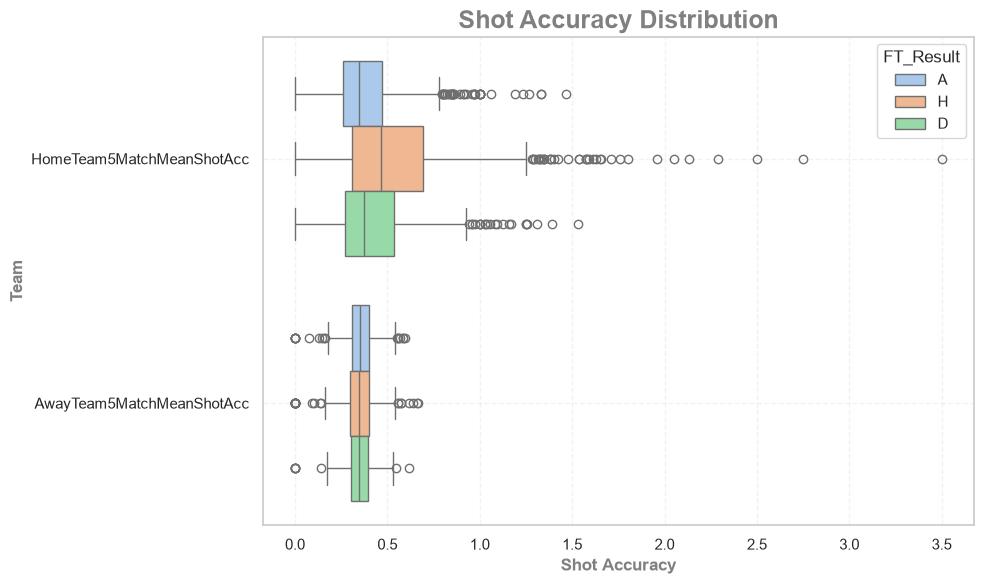

In [43]:
"""
What i am trying to understand is to see if the higher the last 5 match shot accuracy, the higher the chance of winning the game.
The aim is to show engineer a feature to show how good a team is in front of goal on average -> show attacking intent.
"""


train_df['HomeTeam5MatchMeanShotAcc'] = (train_df['HomeTeam5MatchShotsOTMean']/train_df['HomeTeam5MatchShotsMean']).fillna(0)
train_df['AwayTeam5MatchMeanShotAcc'] = (train_df['AwayTeam5MatchShotsOTMean']/train_df['AwayTeam5MatchShotsMean']).fillna(0)

melted_df = train_df[['HomeTeam5MatchMeanShotAcc', 'AwayTeam5MatchMeanShotAcc', 'FT_Result']].melt(
    id_vars=['FT_Result'],       # hue col
    var_name='Team',               # This will contain 'HomeTeam...' and 'AwayTeam...'
    value_name='Shot Accuracy'     # This will contain the actual numeric values
)


plt.figure(
    figsize=(10,6)
)

sns.boxplot(
    data=melted_df,
    x='Shot Accuracy',
    y='Team',
    hue='FT_Result',
    orient='h'
);

#adjust viz
adjust_visuals(
    title="Shot Accuracy Distribution",
    x_label="Shot Accuracy",
    y_label="Team"
);




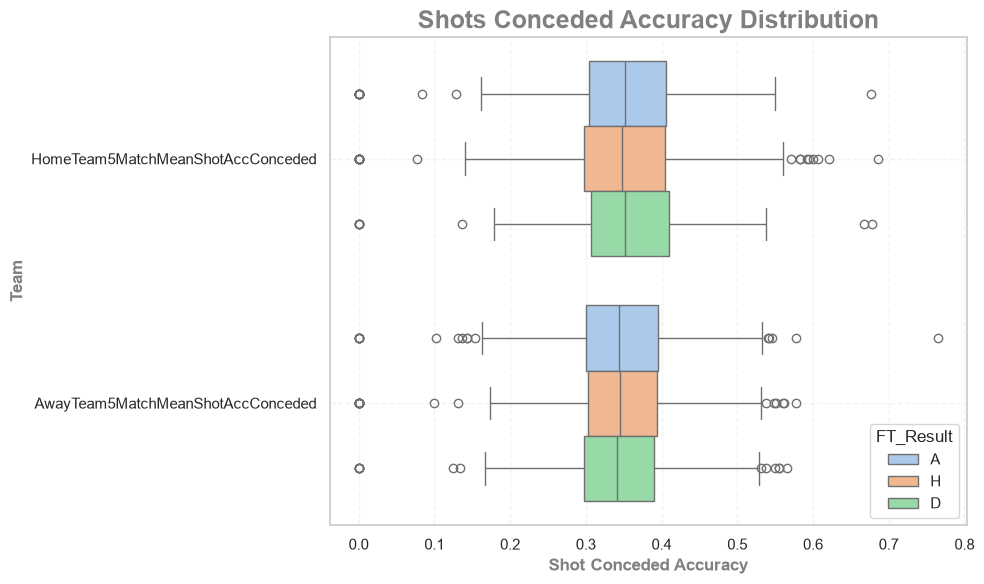

In [44]:
# for conceded, they want a low % value as it can indicate strong defense - ie putting off attackers as they strike.
train_df['HomeTeam5MatchMeanShotAccConceded'] = (train_df['HomeTeam5MatchShotsOTConcededMean']/train_df['HomeTeam5MatchShotsConcededMean']).fillna(0)
train_df['AwayTeam5MatchMeanShotAccConceded'] = (train_df['AwayTeam5MatchShotsOTConcededMean']/train_df['AwayTeam5MatchShotsConcededMean']).fillna(0)

melted_df = train_df[['HomeTeam5MatchMeanShotAccConceded', 'AwayTeam5MatchMeanShotAccConceded', 'FT_Result']].melt(
    id_vars=['FT_Result'],       # hue col
    var_name='Team',               # This will contain 'HomeTeam...' and 'AwayTeam...'
    value_name='Defence Accuracy'     # This will contain the actual numeric values
)

plt.figure(
    figsize=(10,6)
)

sns.boxplot(
    data=melted_df,
    x='Defence Accuracy',
    y='Team',
    hue='FT_Result',
    orient='h'
);

#adjust viz
adjust_visuals(
    title="Shots Conceded Accuracy Distribution",
    x_label="Shot Conceded Accuracy",
    y_label="Team"
);

**Notes**

The attacking and defensive histograms do not provide good signal due to the (roughly) evenly positioned distributions across all outcomes.

However, it does tell me that shot avg shot accuracy (both conceded and given) across 5 games typically lies between 30% and 40%. Across the Premier League teams, this is quite low but is likely impacted by the lower performing teams.

In [45]:
# create the features
x_train,x_val,x_test = shot_acc_feature(x_train),shot_acc_feature(x_val),shot_acc_feature(x_test)

x_train.info()

<class 'pandas.DataFrame'>
Index: 1900 entries, 0 to 379
Data columns (total 89 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Date                                     1900 non-null   datetime64[us]
 1   Time                                     1900 non-null   str           
 2   HomeTeam                                 1900 non-null   str           
 3   AwayTeam                                 1900 non-null   str           
 4   FT_HomeGoals                             1900 non-null   int64         
 5   FT_AwayGoals                             1900 non-null   int64         
 6   FT_Result                                1900 non-null   str           
 7   HT_HomeGoals                             1900 non-null   int64         
 8   HT_AwayGoals                             1900 non-null   int64         
 9   HT_Result                                1900 non-null   s

### Goals

In [46]:
# which teams scores the most goals on avg per game?

scoring_teams = goals_for_and_against_match_avg(train_df,'HomeTeam','FT_HomeGoals')

# create colour matrix
scoring_teams.head(10).style.background_gradient(cmap='Blues')

,HomeTeam,FT_HomeGoals,FT_AwayGoals
14,Man City,2.831579,0.821053
12,Liverpool,2.368421,0.831579
0,Arsenal,2.063158,1.084211
21,Tottenham,1.936842,1.136842
15,Man United,1.863158,1.105263
6,Chelsea,1.705263,1.063158
1,Aston Villa,1.694737,1.421053
11,Leicester,1.657895,1.276316
16,Newcastle,1.652632,1.231579
24,West Ham,1.600000,1.400000


In [47]:
# which teams conceded the most on avg?


conceding_teams = goals_for_and_against_match_avg(train_df,'HomeTeam','FT_AwayGoals')

# create colour matrix
conceding_teams.head(10).style.background_gradient(cmap='Blues')


,HomeTeam,FT_HomeGoals,FT_AwayGoals
17,Norwich,0.815789,2.105263
23,West Brom,0.789474,2.052632
13,Luton,1.473684,1.947368
22,Watford,1.026316,1.921053
19,Sheffield United,0.964912,1.736842
10,Leeds,1.280702,1.684211
20,Southampton,1.197368,1.592105
5,Burnley,0.986842,1.552632
2,Bournemouth,1.210526,1.508772
9,Fulham,1.245614,1.421053


Goals For & Against Correlation: 

               FT_HomeGoals  FT_AwayGoals
FT_HomeGoals           1.0          -0.8
FT_AwayGoals          -0.8           1.0




<Figure size 1000x800 with 0 Axes>

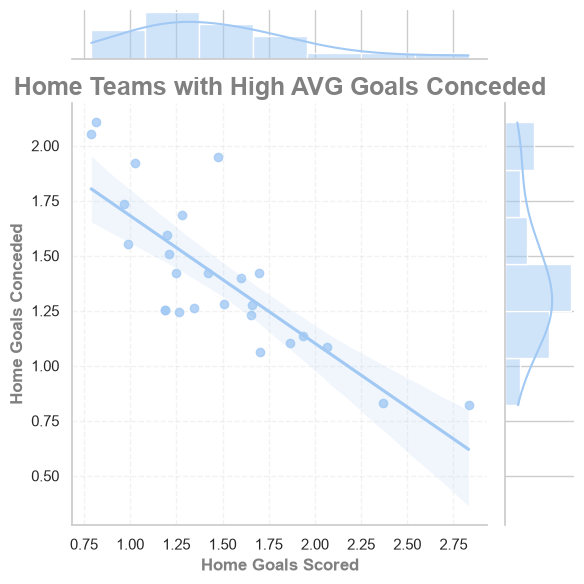

In [48]:
# show the distribution and relationships
corr_tb = conceding_teams.select_dtypes(exclude=['object']).corr()
corr_tb = corr_tb.round(2)
print(f"Goals For & Against Correlation: \n\n {corr_tb}\n\n")
plt.figure(
    figsize=(10,8)
)

sns.jointplot(
    data=conceding_teams,
    x='FT_HomeGoals',
    y='FT_AwayGoals',
    kind='reg'
  )


# format the plot
adjust_visuals(
    title="Home Teams with High AVG Goals Conceded",
    x_label="Home Goals Scored",
    y_label="Home Goals Conceded"
);

In [49]:
# do the same for the away team
# which teams conceded the most on avg?
away_conceding_teams = goals_for_and_against_match_avg(train_df,'AwayTeam','FT_AwayGoals')

# create colour matrix
away_conceding_teams.head(10).style.background_gradient(cmap='Blues')

,AwayTeam,FT_HomeGoals,FT_AwayGoals
14,Man City,0.863158,2.157895
12,Liverpool,1.157895,1.926316
21,Tottenham,1.557895,1.663158
6,Chelsea,1.389474,1.642105
0,Arsenal,1.094737,1.631579
11,Leicester,1.592105,1.605263
15,Man United,1.400000,1.410526
10,Leeds,2.017544,1.385965
3,Brentford,1.649123,1.333333
16,Newcastle,1.684211,1.305263


Goals For & Against Correlation: 

               FT_HomeGoals  FT_AwayGoals
FT_HomeGoals          1.00         -0.65
FT_AwayGoals         -0.65          1.00




<Figure size 1000x800 with 0 Axes>

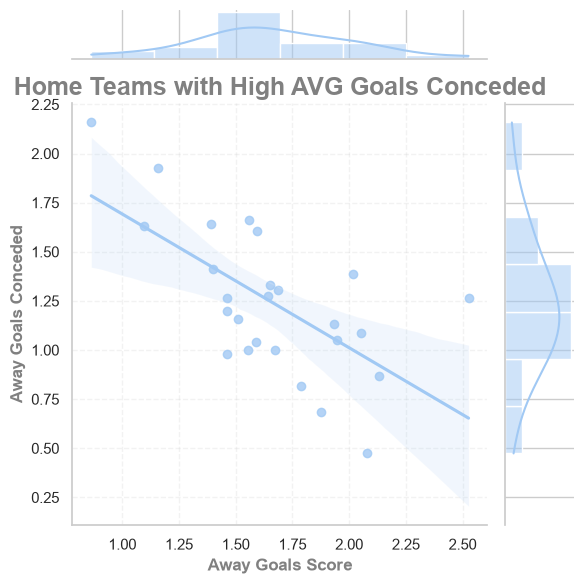

In [50]:
# show the distribution and relationships
corr_tb = away_conceding_teams.select_dtypes(exclude=['object']).corr()
corr_tb = corr_tb.round(2)
print(f"Goals For & Against Correlation: \n\n {corr_tb}\n\n")
plt.figure(
    figsize=(10,8)
)

sns.jointplot(
    data=away_conceding_teams,
    x='FT_HomeGoals',
    y='FT_AwayGoals',
    kind='reg'
  )


# format the plot
adjust_visuals(
    title="Home Teams with High AVG Goals Conceded",
    x_label="Away Goals Score",
    y_label="Away Goals Conceded"
);

**Notes**

More signal! It appears our observations show a strong negative linear relationship between average home team goals scored and conceded per game. This means that, according to the relationship, for every increase in average goals scored per game the teams average goals conceded per game decreases.

When the data was ordered, you could see established Premier league teams scoring the most goals on average per game while lesser established tea,s ie newly promoted teams, typically score less and concede more per game on average.

When I switched the team to away team, the relationship weakened by 0.12 points due to the points on the scatter graph being more spread across the plane. In other words, there is a lot more variability in avg scored and conceded for the away team suggesting groups of teams, although have similar avg goals scored per game, vary more in terms of their goals conceded. From a predictability standpoint, we require further information as to what is influencing the variability - is it the team? is it a group of teams ie newly promoted teams?

For the ML part of this project, we will struggle to predict match outcomes for newly promoted teams as there is little information on them. However, we could use other histroic newly promoted sides as a proxy to extract some information.

What will be intersting to see is how the relationships are observed when we introduce the match outcome.

In [51]:
# create the features
train_df = rolling_goals_for_and_against(train_df)

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1900 entries, 0 to 1899
Columns: 107 entries, Date to AwayTeamLast5GamesGoalsScoredAvg
dtypes: datetime64[us](1), float64(67), int32(1), int64(16), str(22)
memory usage: 1.5 MB


#### Previous Match Influence

Goals For & Against Correlation: 

                              HomeTeamLastGameGoalsScored  FT_HomeGoals
HomeTeamLastGameGoalsScored                         1.00          0.11
FT_HomeGoals                                        0.11          1.00




<Figure size 1000x800 with 0 Axes>

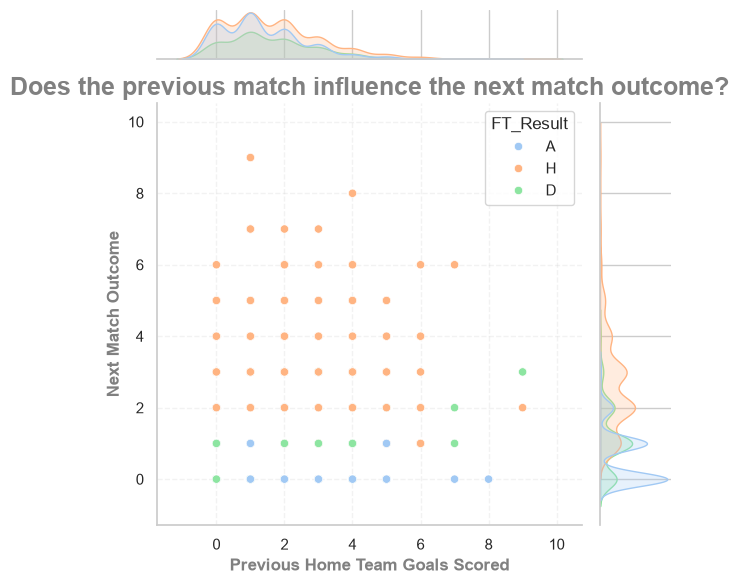

In [52]:
show_the_relartionship(
    df=train_df,
    var1='HomeTeamLastGameGoalsScored',
    var2='FT_HomeGoals',
    result='FT_Result',
    kind='scatter',
    title="Does the previous match influence the next match outcome?",
    x_label="Previous Home Team Goals Scored",
    y_label="Next Match Outcome"
)


Goals For & Against Correlation: 

                                HomeTeamLastGameGoalsConceded  FT_AwayGoals
HomeTeamLastGameGoalsConceded                            1.0           0.1
FT_AwayGoals                                             0.1           1.0




<Figure size 1000x800 with 0 Axes>

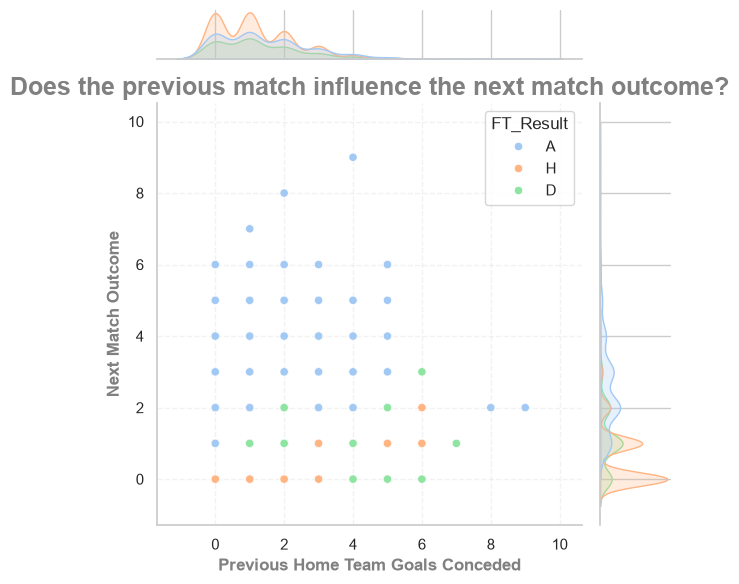

In [53]:
show_the_relartionship(
    df=train_df,
    var1='HomeTeamLastGameGoalsConceded',
    var2='FT_AwayGoals',
    result='FT_Result',
    kind='scatter',
    title="Does the previous match influence the next match outcome?",
    x_label="Previous Home Team Goals Conceded",
    y_label="Next Match Outcome"
)


**Notes**

The relationship shows very little information into the influence of the previous game has on the next. However, a better way to show this data would be to do what we did with the goals - place into buckets and conduct chi2 test!


In [54]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

# create buckets for the goals scored and conceded for both home and away teams

def goal_bucket(goals):
  if goals>=4:
    return '4+'
  elif goals>=2:
    return '2-3'
  else:
    return '0-1'

train_df['HomeGoalsBucket'] = train_df['FT_HomeGoals'].apply(goal_bucket)
train_df['AwayGoalsBucket'] = train_df['FT_AwayGoals'].apply(goal_bucket)

train_df['PreviousMatchHomeGoalsBucket'] = train_df['HomeTeamLastGameGoalsScored'].apply(goal_bucket)
train_df['PreviousMatchAwayGoalsBucket'] = train_df['AwayTeamLastGameGoalsScored'].apply(goal_bucket)



tbl = run_chi2_test(
    var1=train_df['PreviousMatchHomeGoalsBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 19.53
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[350.14736842 240.10105263 465.75157895]
 [227.46315789 155.97473684 302.56210526]
 [ 52.38947368  35.92421053  69.68631579]]
**************************************************


FT_Result,A,D,H
PreviousMatchHomeGoalsBucket,,,
0-1,386,232,438
2-3,210,165,311
4+,34,35,89


In [55]:
train_df['PreviousMatchHomeGoalConcededBucket'] = train_df['HomeTeamLastGameGoalsConceded'].apply(goal_bucket)
train_df['PreviousMatchAwayGoalsConcededBucket'] = train_df['AwayTeamLastGameGoalsConceded'].apply(goal_bucket)


tbl = run_chi2_test(
    var1=train_df['PreviousMatchHomeGoalConcededBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 14.26
P-Value: 0.01
Degrees of Freedom: 4
Expected Value: 
[[401.54210526 275.34315789 534.11473684]
 [193.97368421 133.01052632 258.01578947]
 [ 34.48421053  23.64631579  45.86947368]]
**************************************************


FT_Result,A,D,H
PreviousMatchHomeGoalConcededBucket,,,
0-1,372,279,560
2-3,212,127,246
4+,46,26,32


In [56]:
# review how both features interact
# create contingency table
tbl = run_chi2_test(
    var1=[
        train_df['PreviousMatchHomeGoalConcededBucket'],
        train_df['PreviousMatchHomeGoalsBucket']
          ],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 39.82
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[210.88421053 144.60631579 280.50947368]
 [152.19473684 104.36210526 202.44315789]
 [ 38.46315789  26.37473684  51.16210526]
 [113.73157895  77.98736842 151.28105263]
 [ 67.31052632  46.15578947  89.53368421]
 [ 12.93157895   8.86736842  17.20105263]
 [ 25.53157895  17.50736842  33.96105263]
 [  7.95789474   5.45684211  10.58526316]
 [  0.99473684   0.68210526   1.32315789]]
**************************************************


In [57]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

tbl = run_chi2_test(
    var1=train_df['PreviousMatchAwayGoalsBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl


Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 27.12
P-Value: 0.00
Degrees of Freedom: 4
Expected Value: 
[[400.87894737 274.88842105 533.23263158]
 [194.30526316 133.23789474 258.45684211]
 [ 34.81578947  23.87368421  46.31052632]]
**************************************************


FT_Result,A,D,H
PreviousMatchAwayGoalsBucket,,,
0-1,371,280,558
2-3,202,130,254
4+,57,22,26


In [58]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

tbl = run_chi2_test(
    var1=train_df['PreviousMatchAwayGoalsConcededBucket'],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl

Fail to Reject Null Hypothesis
**************************************************
Chi2 Value: 9.39
P-Value: 0.05
Degrees of Freedom: 4
Expected Value: 
[[350.47894737 240.32842105 466.19263158]
 [227.13157895 155.74736842 302.12105263]
 [ 52.38947368  35.92421053  69.68631579]]
**************************************************


FT_Result,A,D,H
PreviousMatchAwayGoalsConcededBucket,,,
0-1,373,244,440
2-3,211,159,315
4+,46,29,83


In [59]:
"""

the test:

H0: There is no dependency between previous home team goals scored and next match outcome.
H1: There is a dependency between previous home team goals scored and next match outcome.

"""

tbl = run_chi2_test(
    var1=[
        train_df['PreviousMatchAwayGoalsConcededBucket'],
        train_df['PreviousMatchAwayGoalsBucket']
        ],
    target=train_df['FT_Result'],
    confidence=0.05
)

# show the results
tbl

Reject Null Hypothesis -> There is evidence that the features are dependent
**************************************************
Chi2 Value: 40.08
P-Value: 0.00
Degrees of Freedom: 16
Expected Value: 
[[210.55263158 144.37894737 280.06842105]
 [114.39473684  78.44210526 152.16315789]
 [ 25.53157895  17.50736842  33.96105263]
 [151.86315789 104.13473684 202.00210526]
 [ 66.97894737  45.92842105  89.09263158]
 [  8.28947368   5.68421053  11.02631579]
 [ 38.46315789  26.37473684  51.16210526]
 [ 12.93157895   8.86736842  17.20105263]
 [  0.99473684   0.68210526   1.32315789]]
**************************************************


**Notes**

The previous match goals conceded influences the next match a team plays!

1. The mentality effect is non-linear — the impact of conceding 0-1 vs 2-3 is moderate, but 4+ represents a psychological impact on the home team -> a quantification of how conceding 4+ goals influences the teams play in the next home game.

2. The home team scoring 4+ goals in their previous home game suggests something similar - a quantification of confidence in the players that is transferred into the next game!

3. It appears that a match that contains 8+ goals (goals for and against) are a rare event, but when it has happened the next match ended in an away team victory. Due to lack of data, no conclusions should be drawn but I wonder if an exciting previous home game negatively impacts the players mindset?

4. for Away teams, the data tells a different story! We failed to reject the Null hypothesis for Away Team Goals Conceded at the 5% threshold, which means there is little evidence to suggest that the previous match goals conceded for the away team influences their next match. Comparing this to the results obtained for the home teams, it suggests that the goals they concede have minor influence on their performance and mindset into their next away game, whereas the opposite is true for home teams. Perhaps this is the influence of the pressure and attitude applied by the home crowd when they see their team concede lots of goals. In theory, therefore, there is less pressure on away teams going into their next games.

(In theory, i could reject at 10% but I decided not to as I do not want to run the risk of Type 1 Errors)

5. We then observe Simpson Paradox for that feature as the introduction of Goals scored in the previous match for the away team flips the results for us to be able to reject the Null Hypothesis. This means the two features play a key role in determining the match outcome for the next match, meaning the proportion of goals scored relative to conceded influences the Away teams performance - a confidence boost or decline. However, this is likely just a small part of the story as the team they face and their home record will infleunce such matters.

In [60]:
# create the features for train, val and test
x_train,x_val,x_test = rolling_goals_for_and_against(x_train),rolling_goals_for_and_against(x_val),rolling_goals_for_and_against(x_test)

x_train.info()

<class 'pandas.DataFrame'>
Index: 1900 entries, 0 to 379
Columns: 101 entries, Date to AwayTeamLast5GamesGoalsScoredAvg
dtypes: datetime64[us](1), float64(65), int32(1), int64(16), str(18)
memory usage: 1.5 MB


## Probability

### Binomial

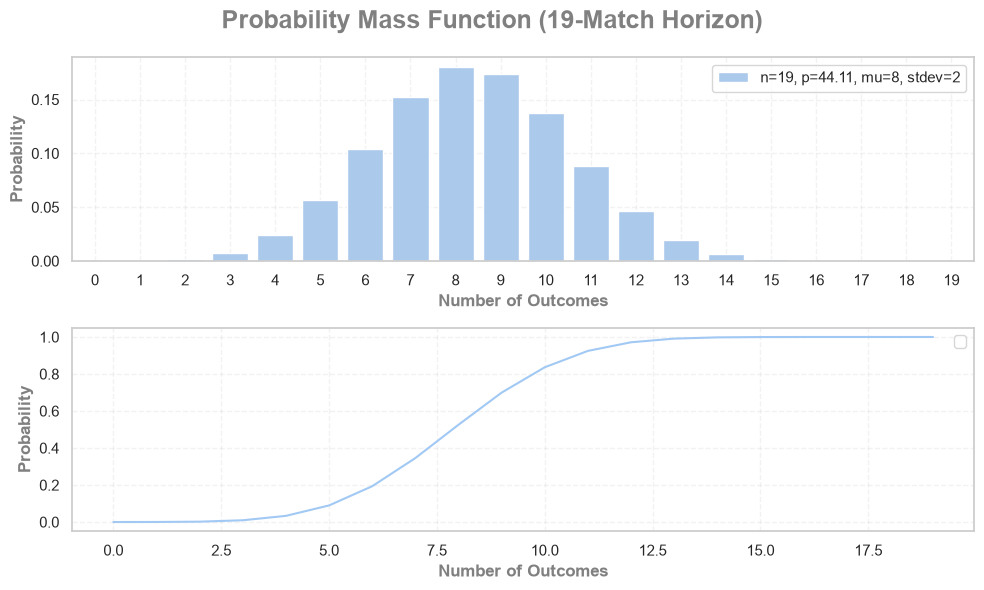

In [62]:
"""
The data we are dealing with has 3 outcomes - win, loss, draw. However, due to the flexibility of the Binomial, we can set win as our target/success while
the other 2 outcomes as fail.

Does our data meet the assumptions?

1. Each match/trial is independent -> although the Chi2 says otherwise, each home match is not played every week, it is more every 1-2 weeks depending
on what events are on such as Cup games. Moreover, each game conatins different teams where their result has no influence on each other.
Therefore, we can assume that each match outcome is independent.
2. p is constant for each trial -> this will be assumed for the purpose of this experiement.
3. We have 2 outcomes.
4. we will fix n trials and our sample size is fixed.


The question we want to answer is what is the expected win per season (19 games) for the home team?

"""
binom_obj = ProbabilityModelling(train_df,'H')

# run binomial
binom_obj.run_model(model_type='binomial',method_of_prep='frequentist')


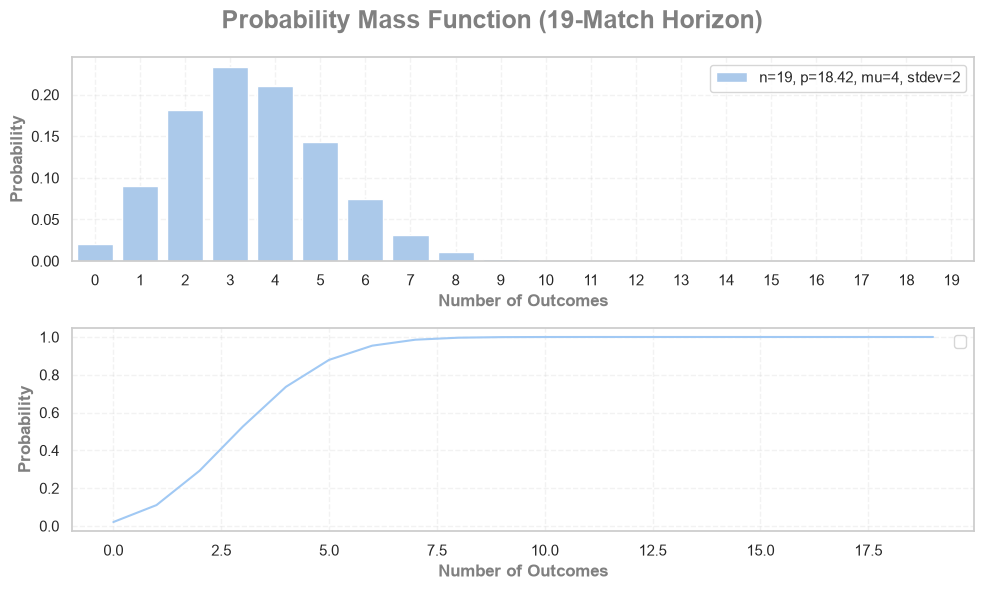

In [78]:
"""
We saw established and new teams to the prem with considerably different goals for and against as home side.

Lets compare the expected wins for these teams to see see their expected wins.
The aim is to see if we can engineer a Prior for these teams to give the model some signal
as to which team should win their next match. Very similar to how we reason with matches in the Premier League, where we expect
strong performing Home sides, such as Man City, to win their next home game, and are shocked when they lose!

I will compare Man City home wins against Norwich.

To make it fair. I will sample the data where they were in the same season.

"""

seasons = train_df['Season'].loc[train_df['HomeTeam']=='Norwich'].unique()

mask = (train_df['Season'].isin(seasons))*(train_df['HomeTeam']=='Norwich')
NorwichDf = train_df.loc[mask]

norwich_obj = ProbabilityModelling(NorwichDf,'H')

# run binomial
norwich_obj.run_model(model_type='binomial',method_of_prep='frequentist')

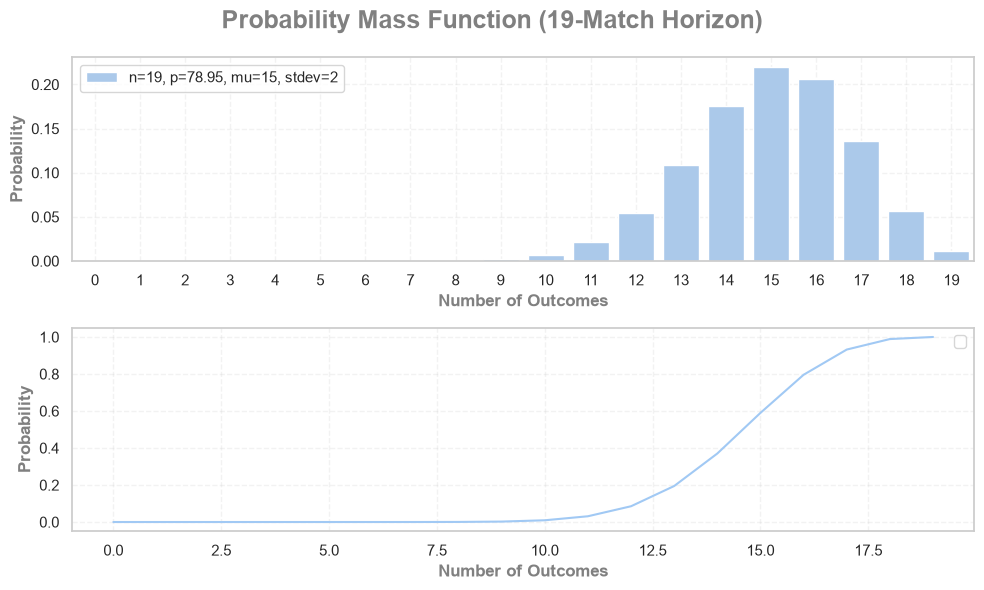

In [79]:
seasons = train_df['Season'].loc[train_df['HomeTeam']=='Norwich'].unique()

mask = (train_df['Season'].isin(seasons))*(train_df['HomeTeam']=='Man City')
McDf = train_df.loc[mask].copy()

mcObj = ProbabilityModelling(McDf,'H')

# run geometric
mcObj.run_model(model_type='binomial',method_of_prep='frequentist')


### Geometric Distribution

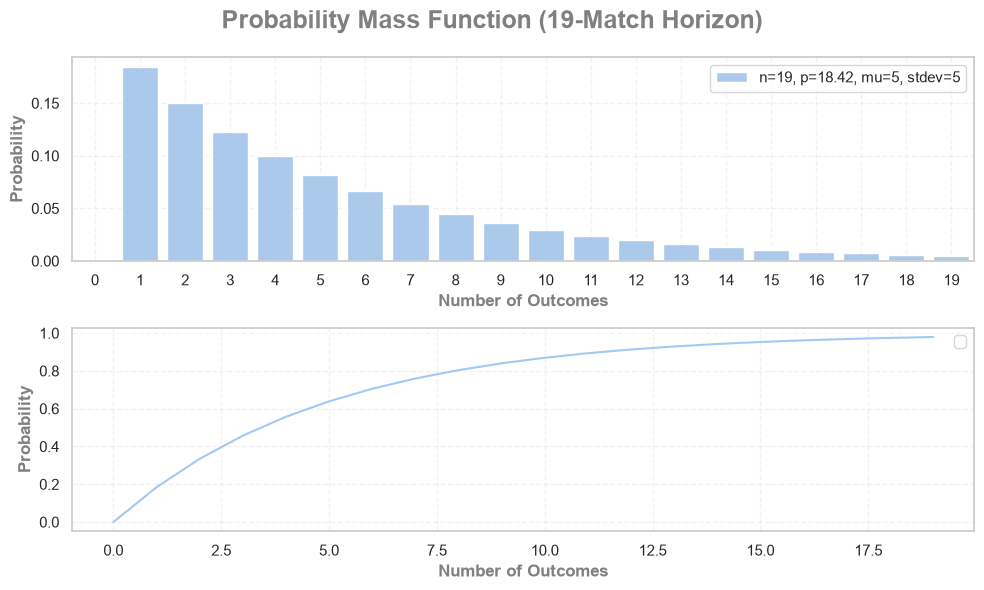

In [80]:
"""
We have observed that expected wins at team level in a season of 19 home games is vastly different, which can give us important information
to identify the outcome by using this data as a Prior (this is to come).

Moreover, it has shown that the team itself is a great feature because the name holds signal relating to its
home or away performance, which enables the model to predict the match outcome. However, feature engineering is likely
required as having all teams as features will be costly, which means we may have to do some feature reduction through PCA.

What we have not observed is how many trials (matches) it will take for these teams to win a game.
In other words, for Norwich and Man City how many matches are they to play until they realise a home win?
Given what we know from the Binomial, I expect Man City to wait, on avg, 1 match while Norwich at least 10.
"""
# run the geometric dist
Norwich_obj = ProbabilityModelling(NorwichDf,'H')
Norwich_obj.run_model(model_type='geometric',method_of_prep='frequentist')

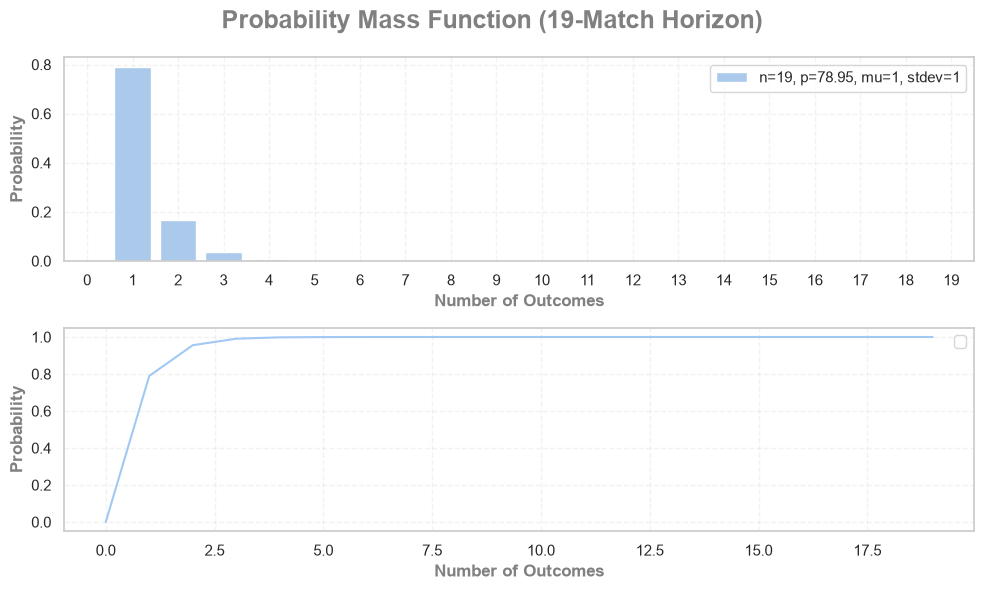

In [ ]:
# run the geometric dist
mc_obj = ProbabilityModelling(McDf,'H')
mc_obj.run_model(model_type='geometric',method_of_prep='frequentist')

**Notes**

The contrasting differences between the successful home team and unsuccessful home team is strikingly different! What we are observing is the quantification of likelihood of a team winning n games in a 19 game season (home games only) and the likelihood of a team winning in their next n games.

For Man City (the strong team), they have a strong likelihood that they will win their next game, whereas Norwich is the opporsite. Their distribution slowly declines after each trial (match), which means that there are small differences in likelihood in Norwich winning a game in n amount if trials. This visualisation shows what a great and a bad home team look like, which links nicely to Bayesian reasoning where fans predict outcomes based on what they have observed (the visuals) which we will explore next.

### Bayesian

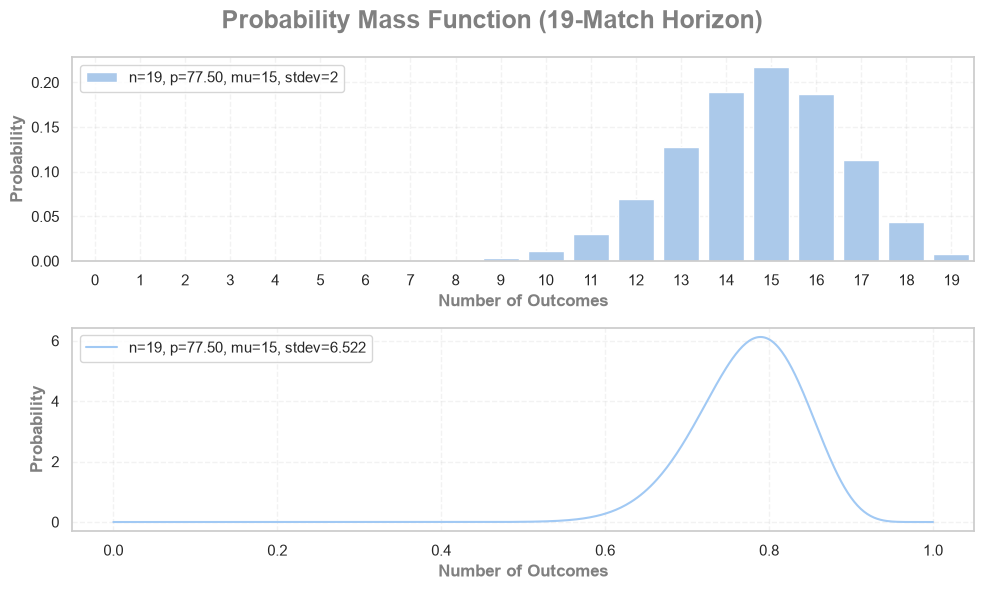

In [82]:
# run beta-binomial
mcObj.run_model(
    model_type='beta-binomial',
    method_of_prep='bayesian',
    prior='uninformative'
    )

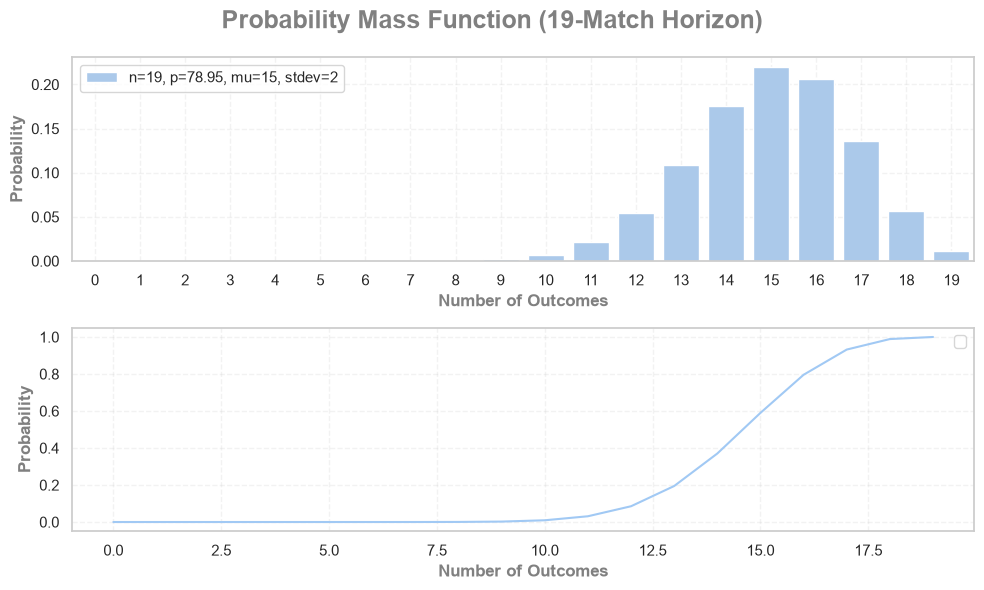

In [68]:
mcObj.run_model(model_type='binomial',method_of_prep='frequentist')

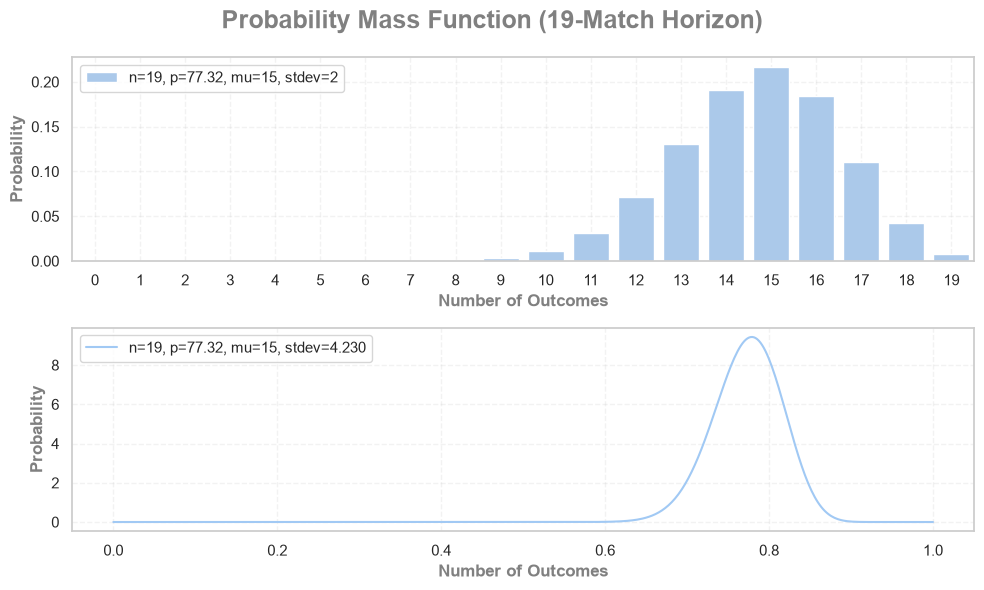

In [ ]:
# what happens when we give the model all the data, what changes when we get more information?
mask = (train_df['HomeTeam']=='Man City')
all_data_McDf = train_df.loc[mask]

all_data_mcObj = ProbabilityModelling(all_data_McDf,'H')

# run the bayesian model
all_data_mcObj.run_model(
    model_type='beta-binomial',
    method_of_prep='bayesian',
    prior='uninformative'
)

**Notes**

the Bayesian analysis shows revealed the following:

1. Too little information (data) leads to a wide Posterior Distribution by using an Uninformative Prior. This is because we were only using 2 seasons-worth of data, which is not a significant amount to make judgements on the outcome. In terms of our ML model, this will be encountered when we come across teams that have not entered the league ever or in a long time - with have no information on how they will likely to perform at home or away. However, as I mentioned earlier, proxies can be used to give some information about these teams. This method is very similar to that of adding in Prior data as to how newly promoted teams performed at home or away historically, how the newly promoted teams performed against established teams or top 6 / big 6. Therefore, I shall create features that will act as prior information in the feature set with the aim to give the model some information to effectively predict the match outcome.

2. By increasing our data size, we shifted our Binomial and Beta to the right -> this is the direct effect of updating our model with new information. However, what I didn't do was update my Prior as I simply gave the model more data. That being said, we still have a tighter Posterior distribution in comparison to using 2 seasons worth of data.

The next step is to see what happens when i update my Priors with new information and how my Posterior and Binomial Distribution will change.

In [84]:
train_df = team_status(df=train_df)
result_df = train_df.pivot_table(
    index='HomeTeamLeagueStatus',
    columns='Season',
    values='FT_Result',
    aggfunc='value_counts'
)

# adjust the df output
add_matrix_colour(result_df, title="Home Team League Status vs Match Result")

In [85]:
"""
We have now increased our information for teams like Norwich, lets see how confident we can be
when we use this data to quantify the likelihood of winning certain number of games in a season
"""

newlyPromoted_mask = train_df['HomeTeamLeagueStatus']=='Newly Promoted'
newlyPromotedDf = train_df.loc[newlyPromoted_mask].copy()

newlyPromoted_proportions = newlyPromotedDf['FT_Result'].value_counts(normalize=True).reset_index()

# adjust the df output
add_matrix_colour(newlyPromoted_proportions, title="Newly Promoted Teams: Match Result Proportions")

,FT_Result,proportion
0,A,0.393092
1,H,0.373355
2,D,0.233553


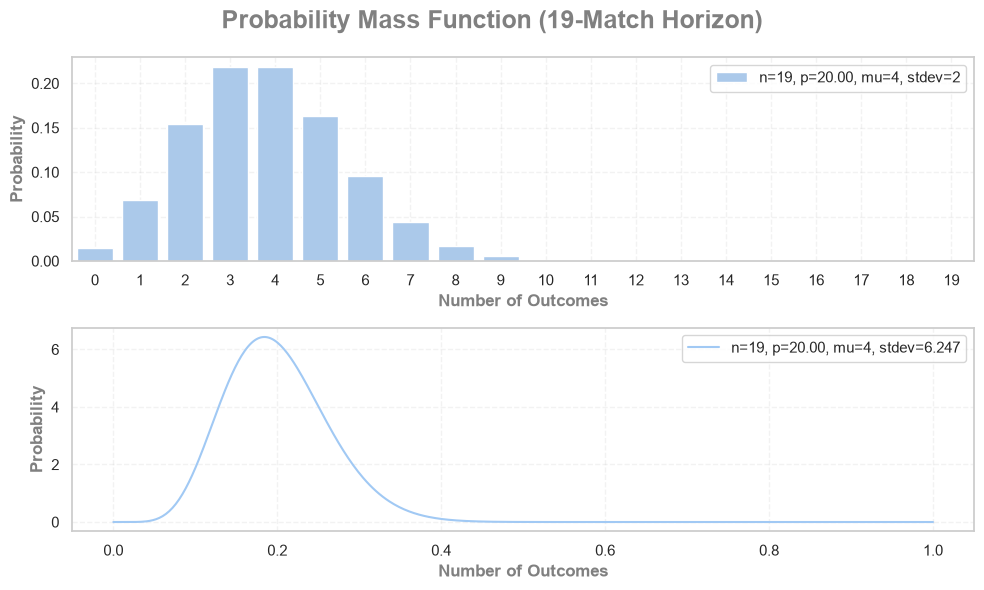

In [ ]:
Norwich_obj.run_model(
    model_type='beta-binomial',
    method_of_prep='bayesian',
    prior='uninformative'
    )

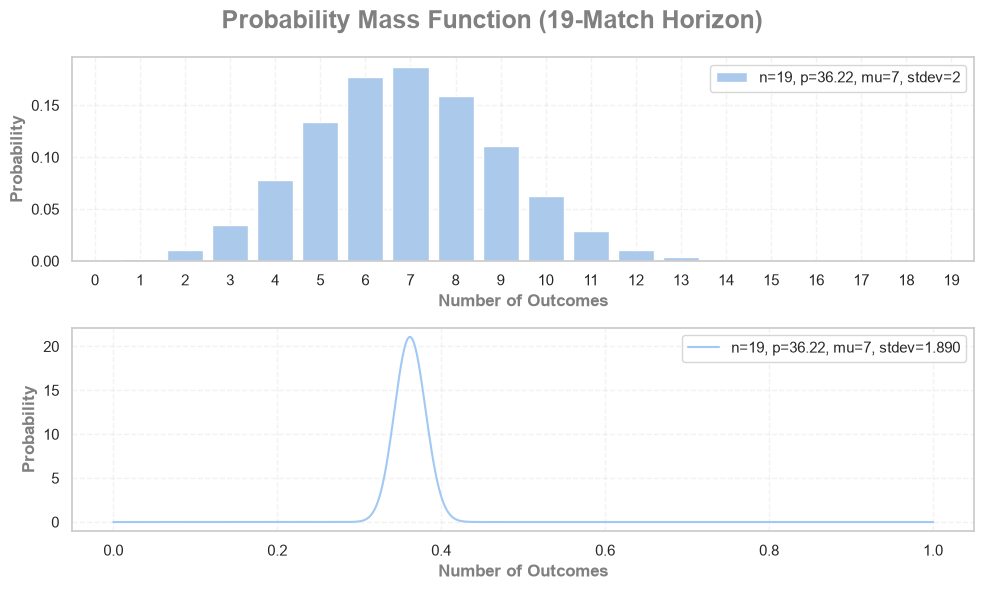

In [73]:
# lets run the probability model
Norwich_obj.run_model(
    model_type='beta-binomial',
    method_of_prep='bayesian',
    prior='global',
    all_data=train_df,
    team_status="Newly Promoted"
    )

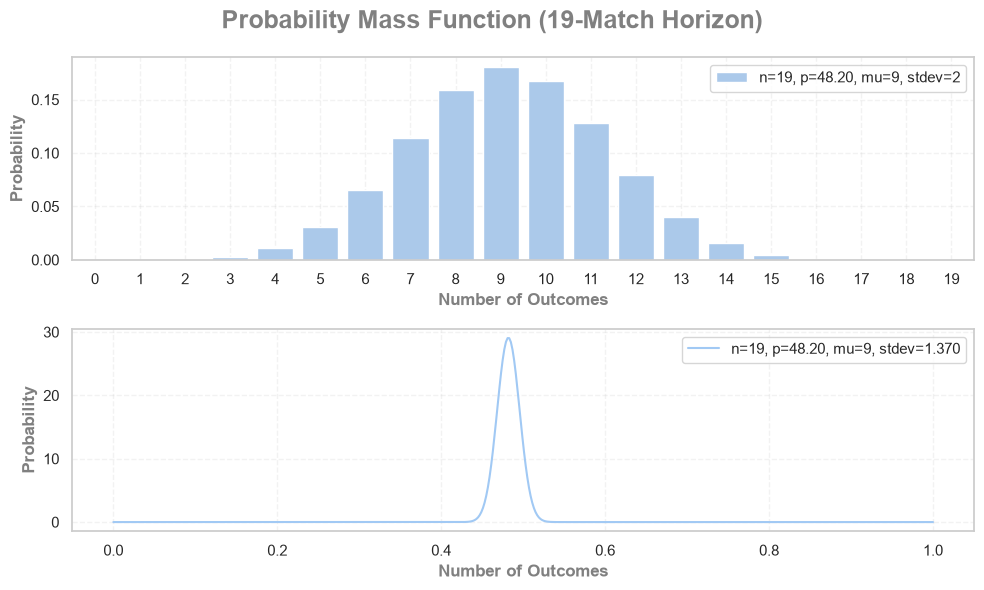

In [87]:
"""
How does this prioir influence Man City?

I am keen to understand whether adding a prior for all established teams
will degrade the Posterior Distribution due to Teams like Fulham and Nottingham Forest.
"""

mcObj = ProbabilityModelling(McDf,'H')
mcObj.run_model(
    model_type='beta-binomial',
    method_of_prep='bayesian',
    prior='global',
    all_data=train_df,
    team_status="Established"
    )

**Notes**

By adding the feature to determine newly promoted teams, I have observed the following:

1. The Posterior Distribution shows increased confidence due to the reduction of the standard deviation - Updating the Prior to Global for Newly Promoted Teams provided the probability model more confident information as to where the probability (p) lies for these teams.

2. For new teams coming into the league, we can expected them to win 5 home games in the season on average. From a supporter standpoint, this is not good at all as each of these new teams need to maximise their home wins due to having the support of the home crowd.

3. It would be interesting to see how the global prior updates with each season as we could see these teams improving by winning more home games. Therefore, it is important that the prior for these types of teams are updated as each game passes.

4. The introduction of the Prior for newly promoted teams has provided the quantification of Football fans belief when they go into seasons not knowing the opposition. For example, a supporter of the away side will be highly confident that they will beat the newly promoted team or draw, but will be shocked for the event that they lose the match.

5. You could argue that the Newly Promoted Team Prior has placed over confidence in Norwich probability of winning a game in the Premier League as it has shifted the distributions to the right (Binomial mu increased by 1 match and Beta mu has increased by 7.63%). However, this signal will provide the ML model signal for teams where we have limited information by using the label and a prior value feature to predict the match outcome. My money is these teams losing or drawing!

6. Finally, when applying the global prior for Man City it draws the distributions to the left which is a visual representation of the dangers of Global Priors. This is because it is being influenced by the teams who are established but do not perform as well as a team like Man City. Therefore, the prior for this type of team should be data from the Top 6 teams, while the remaining will be labelled as either newly promoted or average team.

### Poisson

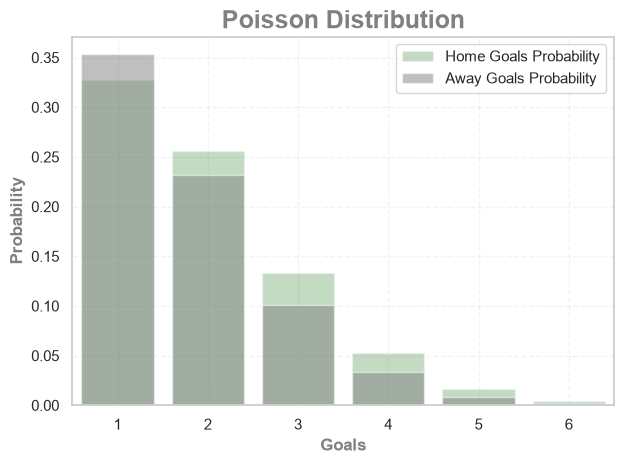

In [75]:
"""
Within this section, I want to find out if i can model the expected goals per game. I can apply the
Poisson Dist because:

1. Each game is roughly 90 minutes long
2. Each match is independent
3. We have count data (Goals)
4. No goal happens at the same time in each match - there is only one ball on the pitch!
"""

# lets just see the global poisson distribution
avg_goals_game = train_df['FT_HomeGoals'].mean()
avg_A_goals_game = train_df['FT_AwayGoals'].mean()

# apply the Poisson
x = range(1,7,1)
poisson_dist = poisson.pmf(x,avg_goals_game)
poisson_A_dist = poisson.pmf(x,avg_A_goals_game)


sns.barplot(
    x=x,
    y=poisson_dist,
    color='green',
    alpha=0.25,
    label="Home Goals Probability"
);
sns.barplot(
    x=x,
    y=poisson_A_dist,
    color='grey',
    alpha=0.5,
    label="Away Goals Probability"
);

# adjust visual
adjust_visuals(
    'Poisson Distribution',
    'Goals',
    'Probability'
)

plt.legend();

In [76]:
"""
Now we have explored this area, lets create a Bayesian-like feature where
we feed the model the expected win, draw and loss % as a rolling feature (the prior)
"""

def rolling_expected_rate_binom(df:pd.DataFrame, team:str) -> pd.DataFrame:
  """
  Within this functino, I will create a running analysis
  where I will apply a binomial distribution for established
  teams in the prem and newly promoted. This will act as a prior for
  our knowledge of these teams.

  There is a clear limitation in that the sheer difference between Fulham and
  Man City who are established teams. However, we have observed a minor influence

  """
  df = df.copy()


In [ ]:
# save the datasets as csv files for ML applications

x_train.to_csv('x_train.csv',index=False)
x_val.to_csv('x_val.csv',index=False)
x_test.to_csv('x_test.csv',index=False)

# now the targets
y_train.to_csv('y_train.csv',index=False)
y_val.to_csv('y_val.csv',index=False)
y_test.to_csv('y_test.csv',index=False)

# Data Transformation

In [88]:
# drop any features we don't need or features that will invoke leakage
features_to_drop = [
    'HomeTeam',
    'AwayTeam',
    'Match Referee',
    'Season',
    'FT_Result',
    'HT_Result',
    'FT_HomeGoals',
    'FT_AwayGoals',
    'HT_HomeGoals',
    'HT_AwayGoals',
    'HomeShots',
    'AwayShots',
    'HomeShotsonTarget',
    'AwayShotsonTarget',
    'HomeFoulsCommitted',
    'AwayFoulsCommitted',
    'HomeCorners',
    'AwayCorners',
    'HomeYellowCards',
    'AwayYellowCards',
    'HomeRedCards',
    'AwayRedCards'
]

# drop the feature list
train_df.drop(columns=features_to_drop,inplace=True)
x_train.drop(columns=features_to_drop,inplace=True)
x_val.drop(columns=features_to_drop,inplace=True)
x_test.drop(columns=features_to_drop,inplace=True)

In [89]:
"""
Here I will create a data transformation pipeline to ready the data for modelling
"""
def data_prep_pipeline(in_df:pd.DataFrame):

  """
  For this function, I will use standard scaler for floats, min max scaler for ints
  and one hot encoder for obj data types
  """

  # build pipelines
  num_pipe = Pipeline([
        ('sc',StandardScaler())
    ])
  pct_pipe = Pipeline([
        ('mm', MinMaxScaler())
    ])
  cat_pipe = Pipeline([
        ('ohe',OneHotEncoder())
    ])


  #num_column = in_df.select_dtypes(include=[]).columns.tolist()
  int_col = in_df.select_dtypes(include=['int64','int32','float64']).columns.tolist()
  cat_column = in_df.select_dtypes(exclude=['float64','int64','int32']).columns.to_list()
  #cat_column.remove('Season')
  # join the two pipes together
  preprocessor = ColumnTransformer([
        #('num',num_pipe,num_column),
        ('cat',cat_pipe,cat_column),
        ('int',pct_pipe,int_col)
    ],remainder='passthrough')

  return preprocessor


In [90]:
processor = data_prep_pipeline(in_df=x_train)

# fit the data
x_train_processed = processor.fit_transform(x_train)
x_val_processed = processor.transform(x_val)
x_test_processed = processor.transform(x_test)

# get feature names
feature_names = processor.get_feature_names_out()

# convert to df
x_train_processed = pd.DataFrame(x_train_processed,columns=feature_names)

ValueError: Found unknown categories [np.datetime64('2024-09-21T00:00:00.000000'), np.datetime64('2024-12-21T00:00:00.000000'), np.datetime64('2024-12-26T00:00:00.000000'), np.datetime64('2025-04-20T00:00:00.000000'), np.datetime64('2024-12-15T00:00:00.000000'), np.datetime64('2024-11-23T00:00:00.000000'), np.datetime64('2025-05-01T00:00:00.000000'), np.datetime64('2025-04-16T00:00:00.000000'), np.datetime64('2025-03-15T00:00:00.000000'), np.datetime64('2024-08-18T00:00:00.000000'), np.datetime64('2025-02-26T00:00:00.000000'), np.datetime64('2024-11-25T00:00:00.000000'), np.datetime64('2024-10-05T00:00:00.000000'), np.datetime64('2024-08-31T00:00:00.000000'), np.datetime64('2025-03-10T00:00:00.000000'), np.datetime64('2025-02-23T00:00:00.000000'), np.datetime64('2025-04-07T00:00:00.000000'), np.datetime64('2025-04-05T00:00:00.000000'), np.datetime64('2025-04-03T00:00:00.000000'), np.datetime64('2024-11-09T00:00:00.000000'), np.datetime64('2025-04-22T00:00:00.000000'), np.datetime64('20

In [91]:
# transfor target
map_dict = {
    'H':2,
    'D':1,
    'A':0
}

y_train = y_train.map(map_dict)
y_val = y_val.map(map_dict)
y_test = y_test.map(map_dict)

### PCA

In [ ]:
"""
Because we have a significant amlunt of features, I will use PCA to reduce them down!
"""

'\nBecause we have a significant amlunt of features, I will use PCA to reduce them down!\n'

# Modelling

## Base model

In [93]:
"""
For this part, I just want to see what features are important, while understadning how well a
base model does with the data we have so far.

First I will run cross validation for time series
then i will fit my data to see what features are important
"""
dt = DecisionTreeClassifier(random_state=42)

models = {
    "Decision Tree": dt
}

run_cross_validation(x_train_processed,y_train,models)

AttributeError: 'csr_matrix' object has no attribute 'iloc'

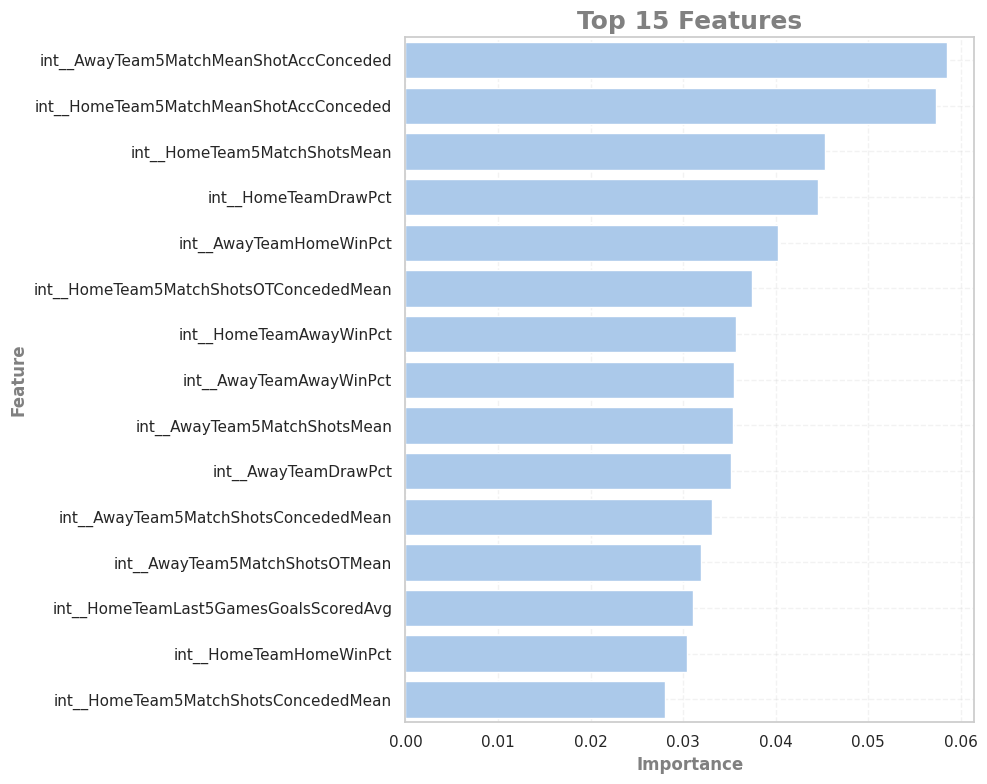

In [ ]:
"""
What are the best features?
"""

dt.fit(x_train_processed,y_train)

# show the top best features
feature_importance = dt.feature_importances_
feature_names_ = list(feature_names)

importance_df = (
    pd.DataFrame(
        list(zip(feature_names_,feature_importance)),
        columns=['Feature','Importance'])
)

top15Features = importance_df.sort_values(by='Importance',ascending=False).head(15)

# show results
plt.figure(
    figsize=(10,8)
)

sns.barplot(
    data=top15Features,
    y='Feature',
    x='Importance'
)

# adjust the visual
adjust_visuals(
    'Top 15 Features',
    'Importance',
    'Feature'
)

**Notes**

The base model that we have created is not very good, but provides some key insights:

1. The likely reason for such bad performance is due to the complexity of the dataset -> high bias caused by too many features.
2. The model appears to favour, although not considerably against the other features, the most recent features -> the last 5 games. Does this mean that teams are influenced by most recent results and form?
3. the Feature importance is fairly spread out where there is no single feature that holds the highest weight, which means there is little chance of data leakage!

I will reduce the complexity of the data by applying PCA and see what happens with our base model.

Before PCA: (2280, 79)
After PCA: (2280, 33)


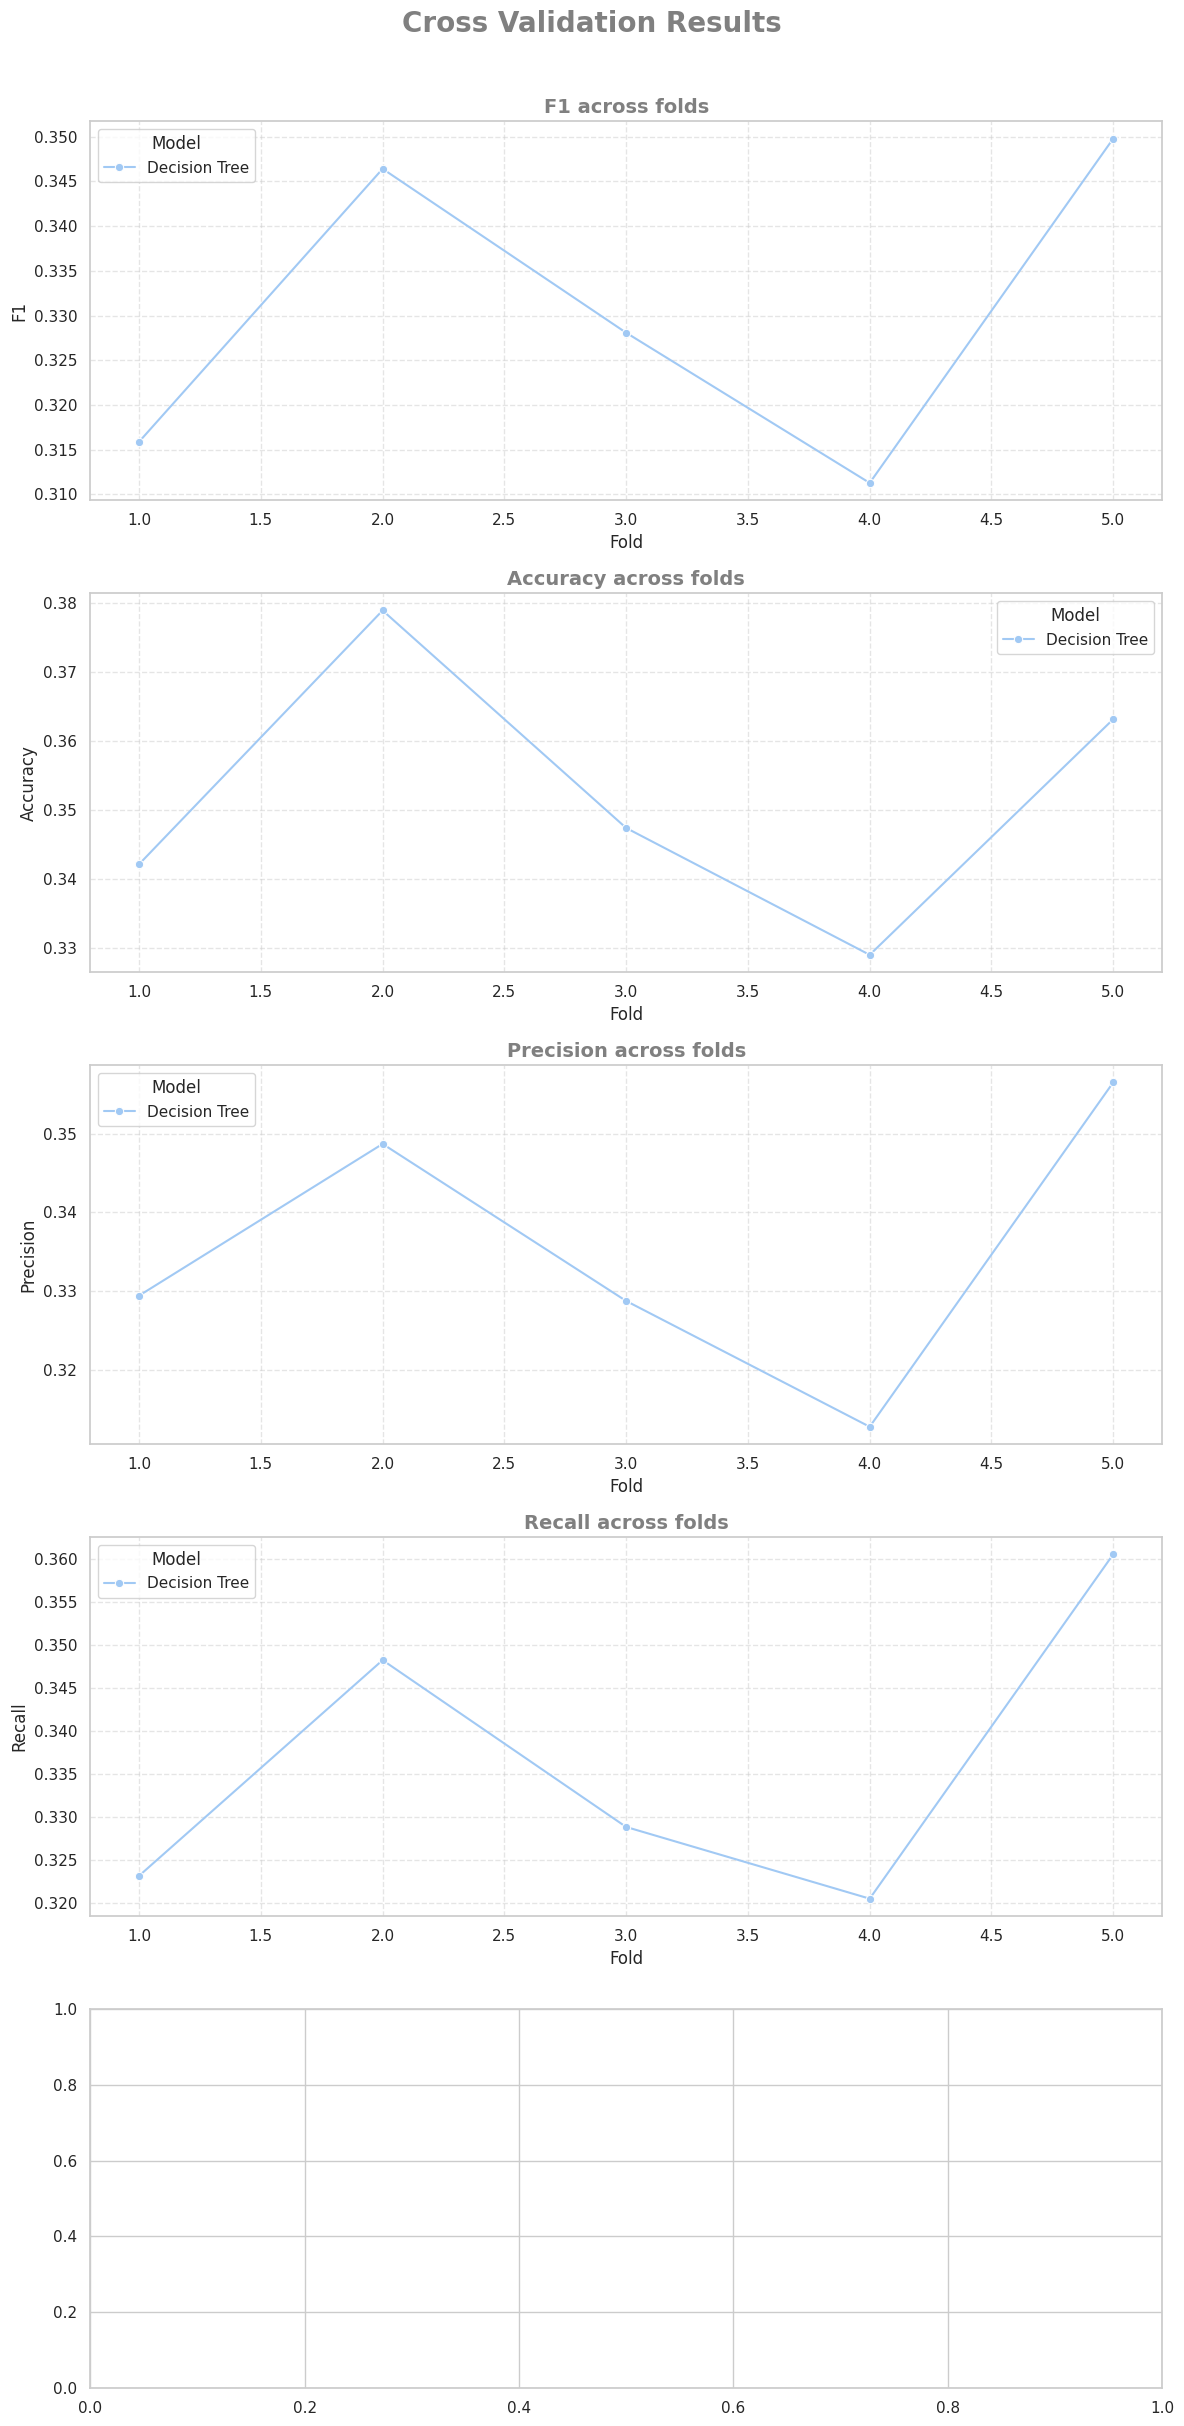

In [ ]:
# lets keep 95% of the information
pca = PCA(n_components=0.95)
pca.fit(x_train_processed)
x_train_pca = pca.transform(x_train_processed)

# now lets see the result
print(f"Before PCA: {x_train_processed.shape}")
print(f"After PCA: {x_train_pca.shape}")

# convert the x_train_pca to df
cols = [i for i in range(1,x_train_pca.shape[1]+1)]
x_train_pca_ = pd.DataFrame(x_train_pca,columns=cols)

run_cross_validation(x_train_pca_,y_train,models)

              precision    recall  f1-score   support

           0       0.32      0.28      0.30       132
           1       0.22      0.22      0.22        93
           2       0.42      0.46      0.44       155

    accuracy                           0.34       380
   macro avg       0.32      0.32      0.32       380
weighted avg       0.33      0.34      0.34       380



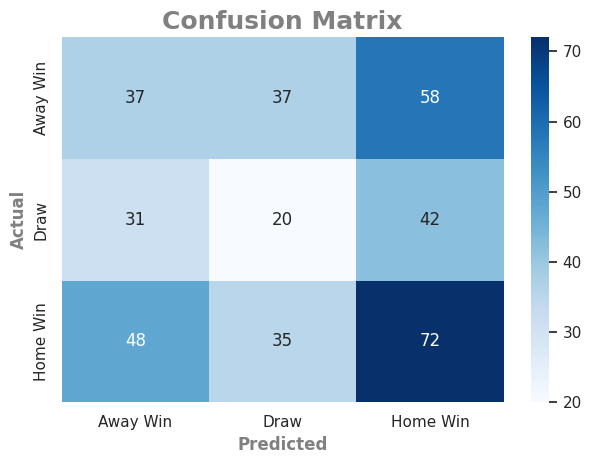

In [ ]:
# lets see where our base model is going wrong by using the validation as our
# "test" set.

dt.fit(x_train_processed,y_train)
y_pred = dt.predict(x_val_processed)

# compare with actual
print(classification_report(y_val,y_pred))

# print confusion matrix
target_labels = ['Away Win','Draw','Home Win']
mtx = confusion_matrix(y_val,y_pred)
sns.heatmap(
    mtx,
    annot=True,
    fmt='g',
    cmap='Blues',
    xticklabels=target_labels,
    yticklabels=target_labels
);




#adjust viz
adjust_visuals(
    'Confusion Matrix',
    'Predicted',
    'Actual'

)
